# GridMind v2: an AI trader for a GB grid battery

**OxHack 26 — Best use of data for predictions and decisions**

Every 30 minutes, Britain's grid batteries must decide whether to **charge, discharge or hold** before they know the price.

**Pipeline**
1. **Data:** real GB market data from Elexon (free, no key).
2. **Data quality + leak-free cleaning.**
3. **EDA:** how prices behave, what drives them, and how the market shifted over the year.
4. **Features:** only information available at decision time.
5. **Model comparison:** simple baselines vs LightGBM, retrained every two weeks (walk-forward), **chosen by validation profit**, not just accuracy.
6. **Decision engine:** a rolling 22-hour optimiser for a 50 MW / 100 MWh battery.
7. **Honest backtest** on unseen months.
8. **Deployment:** saved model + a live web app (Gradio) with a public link for the judges.

Runtime → Run all. If `gb_power_data.csv` from your first run is in the Colab files panel (or uploaded), the download is skipped.

**What this does:** Loads the libraries and sets the battery we simulate: 50 MW power, 100 MWh storage, 88% round-trip efficiency, GBP 5/MWh wear cost. These match a typical new British 2-hour grid battery.

In [1]:
# ===== 1. Setup =====
import sys, subprocess
try:
    import lightgbm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm

import os, time, warnings
from datetime import date, datetime, timedelta, timezone
import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt
from scipy.optimize import linprog
import joblib
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# ---- Data range: one year is ideal; start with ~60 days to test quickly ----
START = date(2025, 10, 1)
END   = date.today() - timedelta(days=2)

# ---- Battery: a typical new GB 2-hour site ----
P_MAX_MW   = 50.0                 # power
E_MAX_MWH  = 100.0                # energy capacity
SOC_MIN, SOC_MAX = 5.0, 95.0      # MWh limits (protects the battery)
RTE        = 0.88                 # round-trip efficiency
ETA        = RTE ** 0.5           # one-way efficiency (charge and discharge)
DEG_COST   = 5.0                  # GBP per MWh discharged (wear), stated assumption
DT         = 0.5                  # hours per settlement period
E_STEP     = P_MAX_MW * DT        # max grid-side MWh per half-hour (25)
SOC_START  = 50.0

DATA_FILE = "gb_power_data.csv"
TUNE_MODELS = True    # small hyperparameter search on validation months (adds ~3-5 min); False = defaults
print("Data range:", START, "to", END)

Data range: 2025-10-01 to 2026-10-22


**What this does:** Functions that download five public datasets from Elexon's free API: imbalance prices (what we predict), generation by fuel type, the wholesale market price, and every published wind and demand forecast. One request per day or week, retried if it fails.

In [2]:
# ===== 2. Data fetchers (Elexon Insights API, public, no key) =====
BASE = "https://data.elexon.co.uk/bmrs/api/v1"
S = requests.Session()

def get(url, params=None, retries=3):
    err = None
    for _ in range(retries):
        try:
            r = S.get(url, params=params, timeout=90)
            if r.status_code == 429:
                time.sleep(5); continue
            r.raise_for_status()
            js = r.json()
            return js["data"] if isinstance(js, dict) and "data" in js else js
        except Exception as e:
            err = e; time.sleep(2)
    print(f"   ! request failed: {url} {params or ''} -> {err}")
    return []

def chunks(start, end, days=7):
    d = start
    while d <= end:
        e = min(d + timedelta(days=days - 1), end)
        yield d, e
        d = e + timedelta(days=1)

def iso(d):  # date -> ISO midnight UTC
    return f"{d.isoformat()}T00:00:00Z"

def fetch_prices(start, end):
    # Imbalance (system) price per half-hour -> our TARGET
    rows = []
    d = start
    while d <= end:
        rows += get(f"{BASE}/balancing/settlement/system-prices/{d.isoformat()}")
        print(f"   prices {d}", end="\r"); d += timedelta(days=1)
    print()
    df = pd.DataFrame(rows)
    if df.empty: return df
    df = df[["startTime", "systemSellPrice", "netImbalanceVolume"]].rename(
        columns={"systemSellPrice": "price", "netImbalanceVolume": "niv"})
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    return df.drop_duplicates("startTime", keep="last")

def fetch_fuel(start, end):
    # Generation by fuel type every 5 min -> half-hourly averages
    rows = []
    for a, b in chunks(start, end):
        rows += get(f"{BASE}/datasets/FUELINST/stream",
                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})
        print(f"   fuel mix to {b}", end="\r")
    print()
    df = pd.DataFrame(rows)
    if df.empty: return df
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True).dt.floor("30min")
    return (df.pivot_table(index="startTime", columns="fuelType", values="generation", aggfunc="mean")
              .add_prefix("gen_").reset_index())

def fetch_mid(start, end):
    # Market Index Data: wholesale price per half-hour (volume-weighted across providers)
    rows = []
    for a, b in chunks(start, end):
        rows += get(f"{BASE}/datasets/MID", {"from": iso(a), "to": iso(b + timedelta(days=1))})
    df = pd.DataFrame(rows)
    if df.empty: return df
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    df["pv"] = df["price"] * df["volume"]
    g = df.groupby("startTime")[["pv", "volume", "price"]].agg({"pv": "sum", "volume": "sum", "price": "mean"})
    g["market_price"] = np.where(g["volume"] > 0, g["pv"] / g["volume"].replace(0, np.nan), g["price"])
    return g[["market_price"]].reset_index()

def fetch_forecast(dataset, start, end, value_col):
    # Every published forecast (with publishTime) so we can use only what was known at the time
    rows = []
    for a, b in chunks(start - timedelta(days=2), end):
        rows += get(f"{BASE}/datasets/{dataset}/stream",
                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})
        print(f"   {dataset} to {b}", end="\r")
    print()
    df = pd.DataFrame(rows)
    if df.empty or value_col not in df.columns: return pd.DataFrame()
    df = df[["publishTime", "startTime", value_col]].rename(columns={value_col: "value"})
    df["publishTime"] = pd.to_datetime(df["publishTime"], utc=True)
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    return df.dropna()

def fetch_all(start, end):
    print("Fetching imbalance prices..."); prices = fetch_prices(start, end)
    print("Fetching fuel mix...");         fuel   = fetch_fuel(start, end)
    print("Fetching market index...");     mid    = fetch_mid(start, end)
    print("Fetching wind forecasts...");   windf  = fetch_forecast("WINDFOR", start, end, "generation")
    print("Fetching demand forecasts..."); demf   = fetch_forecast("NDF", start, end, "demand")
    for name, d in [("prices", prices), ("fuel", fuel), ("mid", mid), ("wind fc", windf), ("demand fc", demf)]:
        print(f"   {name:10s}: {len(d):>8,} rows" + ("   <-- EMPTY (feature will be skipped)" if d.empty else ""))
    return prices, fuel, mid, windf, demf

**What this does:** Puts everything on one timeline, one row per half-hour. For forecasts, `asat` picks only the latest forecast that was **already published** at least 1 hour (or 24 hours for day-ahead) before that half-hour, so the model never sees anything from the future.

In [3]:
# ===== 3. Combine into one half-hourly table (as-at forecasts, no look-ahead) =====
FC_LEAD = pd.Timedelta("60min")   # only use forecasts published >= 1 hour before the period
DA_LEAD = pd.Timedelta("24h")     # day-ahead version: published >= 24h before, so usable for any plan step

def asat(fc, times, lead=FC_LEAD, hourly=False):
    # For each target time, the latest forecast for that time published at least `lead` earlier
    if fc.empty: return pd.Series(np.nan, index=times)
    t = pd.DataFrame({"startTime": times})
    t["key"] = t["startTime"].dt.floor("60min") if hourly else t["startTime"]
    t["cutoff"] = t["startTime"] - lead
    f = fc.rename(columns={"startTime": "key"}).sort_values("publishTime")
    out = pd.merge_asof(t.sort_values("cutoff"), f, left_on="cutoff", right_on="publishTime",
                        by="key", direction="backward")
    return out.set_index("startTime")["value"].reindex(times)

def combine(prices, fuel, mid, windf, demf, extend_periods=0):
    t0 = prices["startTime"].min()
    t1 = prices["startTime"].max() + pd.Timedelta(minutes=30) * extend_periods
    grid = pd.DataFrame({"startTime": pd.date_range(t0, t1, freq="30min", tz="UTC")})
    df = grid.merge(prices, on="startTime", how="left")
    for extra in (fuel, mid):
        if len(extra): df = df.merge(extra, on="startTime", how="left")
    hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()
    df["wind_fc"]   = asat(windf, df["startTime"], hourly=hourly).values
    df["demand_fc"] = asat(demf, df["startTime"]).values
    df["wind_fc_da"]   = asat(windf, df["startTime"], lead=DA_LEAD, hourly=hourly).values
    df["demand_fc_da"] = asat(demf, df["startTime"], lead=DA_LEAD).values
    return df

**What this does:** Downloads the data the first time and saves it to `gb_power_data.csv`; later runs just load the file in seconds.

In [4]:
# ===== 3b. Download (or load cached) data =====
if os.path.exists(DATA_FILE):
    raw = pd.read_csv(DATA_FILE, parse_dates=["startTime"])
    print("Loaded cached", DATA_FILE, raw.shape)
    if "wind_fc_da" not in raw.columns:      # file from an older run: add the day-ahead forecasts once
        print("Adding day-ahead wind and demand forecasts to the cached data...")
        t_ = pd.to_datetime(raw["startTime"], utc=True)
        s_, e_ = t_.min().date(), t_.max().date()
        windf = fetch_forecast("WINDFOR", s_, e_, "generation"); demf = fetch_forecast("NDF", s_, e_, "demand")
        hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()
        raw["wind_fc_da"]   = asat(windf, t_, lead=DA_LEAD, hourly=hourly).values
        raw["demand_fc_da"] = asat(demf, t_, lead=DA_LEAD).values
        raw.to_csv(DATA_FILE, index=False)
        print("Upgraded", DATA_FILE, raw.shape)
else:
    prices, fuel, mid, windf, demf = fetch_all(START, END)
    if prices.empty:
        raise SystemExit("No price data came back. Check the internet connection, then open the failing "
                         "URL printed above in a browser to see Elexon's error message.")
    raw = combine(prices, fuel, mid, windf, demf)
    raw.to_csv(DATA_FILE, index=False)
    print("Saved", DATA_FILE, raw.shape)
print(f"Day-ahead forecasts available for {raw['wind_fc_da'].notna().mean():.0%} (wind) and "
      f"{raw['demand_fc_da'].notna().mean():.0%} (demand) of half-hours")
raw.tail()

Fetching imbalance prices...
   prices 2026-10-22
Fetching fuel mix...
   fuel mix to 2026-10-22
Fetching market index...
Fetching wind forecasts...
   WINDFOR to 2026-10-22
Fetching demand forecasts...
   NDF to 2026-10-22
   prices    :   18,576 rows
   fuel      :   18,577 rows
   mid       :   18,577 rows
   wind fc   :  226,957 rows
   demand fc : 1,095,428 rows
Saved gb_power_data.csv (18576, 28)
Day-ahead forecasts available for 100% (wind) and 83% (demand) of half-hours


,startTime,price,niv,gen_BIOMASS,gen_CCGT,gen_COAL,gen_INTELEC,gen_INTEW,gen_INTFR,gen_INTGRNL,...,gen_OCGT,gen_OIL,gen_OTHER,gen_PS,gen_WIND,market_price,wind_fc,demand_fc,wind_fc_da,demand_fc_da
18571,2026-10-22 20:30:00+00:00,219.90,714.876800,3220.500000,8295.000000,0.0,0.0,-211.833333,2000.000000,-195.333333,...,0.0,0.0,809.000000,329.500000,4985.666667,185.24,4924,29903,6147,30233.0
18572,2026-10-22 21:00:00+00:00,219.90,720.456409,3222.166667,6588.500000,0.0,0.0,-128.500000,2002.333333,-347.166667,...,0.0,0.0,514.666667,354.833333,5573.500000,182.34,5789,27949,6596,28338.0
18573,2026-10-22 21:30:00+00:00,209.90,556.412184,3208.500000,3816.000000,0.0,0.0,-143.666667,2002.000000,-486.166667,...,0.0,0.0,701.666667,462.833333,6400.333333,179.73,5789,26087,6596,26857.0
18574,2026-10-22 22:00:00+00:00,209.90,564.655556,3171.333333,2470.833333,0.0,0.0,-191.000000,2002.000000,-513.833333,...,0.0,0.0,445.000000,210.833333,7152.333333,171.59,7468,24570,7426,25166.0
18575,2026-10-22 22:30:00+00:00,137.31,142.539722,3097.833333,2164.500000,0.0,0.0,-339.666667,2002.000000,-513.666667,...,0.0,0.0,175.666667,29.166667,8125.166667,137.31,7468,24300,7426,24020.0


## Data quality and cleaning

Rules: **never invent prices** (the target), **keep price spikes** (they are real and they are where the money is), and **only fill gaps from the past** (forward-fill), because interpolating from future values would leak information.

**What this does:** Checks the raw data before using it: duplicates, missing half-hours, missing values, columns that never change, extreme prices and clock-change days.

In [5]:
# ===== 4. Data quality report =====
if "raw" not in globals():   # the download cell (3b) was skipped: load the saved file or download now
    if os.path.exists(DATA_FILE):
        raw = pd.read_csv(DATA_FILE, parse_dates=["startTime"]); print("Loaded", DATA_FILE)
    else:
        _p, _f, _m, _w, _d = fetch_all(START, END)
        raw = combine(_p, _f, _m, _w, _d); raw.to_csv(DATA_FILE, index=False)
dq = raw.copy()
dq["startTime"] = pd.to_datetime(dq["startTime"], utc=True)
full = pd.date_range(dq.startTime.min(), dq.startTime.max(), freq="30min", tz="UTC")
print(f"Rows: {len(dq):,}   Range: {dq.startTime.min():%d %b %Y} -> {dq.startTime.max():%d %b %Y}")
print(f"Duplicate timestamps: {dq.startTime.duplicated().sum()}   "
      f"Missing half-hours in the timeline: {len(full.difference(dq.startTime))}")
miss = dq.isna().mean().mul(100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print("\nMissing values (% of rows):", "none" if miss.empty else "")
if not miss.empty: print(miss.to_string())
num = dq.select_dtypes("number")
const = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
print("\nConstant columns (carry no information):", const or "none")
p = dq["price"].dropna()
print(f"\nImbalance price: min GBP{p.min():,.0f} | median GBP{p.median():,.0f} | max GBP{p.max():,.0f}")
print(f"  negative: {(p < 0).mean():.1%} of half-hours | above GBP300: {(p > 300).mean():.1%} | "
      f"99th percentile: GBP{p.quantile(0.99):,.0f}")
per_day = dq.startTime.dt.tz_convert("Europe/London").dt.date.value_counts()
print(f"Clock-change days (46 or 50 half-hours): {int(per_day.isin([46, 50]).sum())} "
      "(handled by working in UTC)")

Rows: 18,576   Range: 30 Sep 2025 -> 22 Oct 2026
Duplicate timestamps: 0   Missing half-hours in the timeline: 0

Missing values (% of rows): 
demand_fc_da    16.67
gen_BIOMASS      0.01
gen_COAL         0.01
gen_INTELEC      0.01
gen_INTEW        0.01
gen_CCGT         0.01
gen_INTFR        0.01
gen_INTGRNL      0.01
gen_INTIRL       0.01
gen_INTIFA2      0.01
gen_INTNEM       0.01
gen_INTNSL       0.01
gen_INTVKL       0.01
gen_INTNED       0.01
gen_NPSHYD       0.01
gen_NUCLEAR      0.01
gen_OIL          0.01
gen_OCGT         0.01
gen_OTHER        0.01
gen_PS           0.01
gen_WIND         0.01
market_price     0.01

Constant columns (carry no information): ['gen_OIL']

Imbalance price: min GBP-98 | median GBP97 | max GBP800
  negative: 4.3% of half-hours | above GBP300: 0.2% | 99th percentile: GBP237
Clock-change days (46 or 50 half-hours): 2 (handled by working in UTC)


**What this does:** Fixes problems with simple, explainable rules: remove duplicates, drop useless columns, fix impossible values, and fill short gaps **only from earlier values** (filling from later values would leak the future). Prices are never invented and spikes are kept: they are real and they are where a battery makes money.

In [6]:
# ===== 5. Leak-free cleaning =====
FILL_LIMIT = 4   # forward-fill feature gaps up to 2 hours; longer gaps stay missing

def clean_data(raw, verbose=True):
    df = raw.copy()
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    n_dup = df.startTime.duplicated().sum()
    df = df.drop_duplicates("startTime", keep="last").sort_values("startTime")
    grid = pd.date_range(df.startTime.min(), df.startTime.max(), freq="30min", tz="UTC")
    n_gap = len(grid) - len(df)
    df = df.set_index("startTime").reindex(grid).rename_axis("startTime").reset_index()

    # 1. drop columns with no information (e.g. coal after 2024) or mostly missing
    num = df.select_dtypes("number").columns
    drop = [c for c in num if c not in ("price", "niv", "market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da")
            and (df[c].nunique(dropna=True) <= 1 or df[c].isna().mean() > 0.5)]
    df = df.drop(columns=drop)

    # 2. physically impossible values
    gen_cols = [c for c in df.columns if c.startswith("gen_")]
    clip_cols = [c for c in gen_cols if not c.startswith("gen_INT") and c != "gen_PS"]   # imports/pumping can be negative
    n_clip = int(sum((df[c] < 0).sum() for c in clip_cols))
    for c in clip_cols: df[c] = df[c].clip(lower=0)
    n_bad_fc = 0
    if "wind_fc" in df:   n_bad_fc += int((df.wind_fc < 0).sum());   df.loc[df.wind_fc < 0, "wind_fc"] = np.nan
    if "wind_fc_da" in df: n_bad_fc += int((df.wind_fc_da < 0).sum()); df.loc[df.wind_fc_da < 0, "wind_fc_da"] = np.nan
    if "demand_fc_da" in df: n_bad_fc += int((df.demand_fc_da <= 0).sum()); df.loc[df.demand_fc_da <= 0, "demand_fc_da"] = np.nan
    if "demand_fc" in df: n_bad_fc += int((df.demand_fc <= 0).sum()); df.loc[df.demand_fc <= 0, "demand_fc"] = np.nan

    # 3. fill short feature gaps from the PAST only (never the target)
    feat_cols = gen_cols + [c for c in ("market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da") if c in df]
    before = int(df[feat_cols].isna().sum().sum())
    df[feat_cols] = df[feat_cols].ffill(limit=FILL_LIMIT)
    n_fill = before - int(df[feat_cols].isna().sum().sum())

    if verbose:
        print(f"Removed {n_dup} duplicate rows; added {n_gap} empty rows for missing half-hours (kept as gaps)")
        print(f"Dropped uninformative columns: {drop or 'none'}")
        print(f"Clipped {n_clip} negative generation values to 0; removed {n_bad_fc} impossible forecasts")
        print(f"Forward-filled {n_fill:,} short feature gaps (<= {FILL_LIMIT * 30} min). Prices left untouched.")
        print(f"Half-hours with a usable price: {df.price.notna().sum():,} of {len(df):,}")
    return df

clean = clean_data(raw)

Removed 0 duplicate rows; added 0 empty rows for missing half-hours (kept as gaps)
Dropped uninformative columns: ['gen_OIL']
Clipped 0 negative generation values to 0; removed 0 impossible forecasts
Forward-filled 1,548 short feature gaps (<= 120 min). Prices left untouched.
Half-hours with a usable price: 18,576 of 18,576


## Exploratory data analysis

Each chart is followed by printed findings you can put straight on a slide.

**What this does:** How the price behaves: level over the year, distribution, the daily shape (the battery's core opportunity) and month-to-month changes.

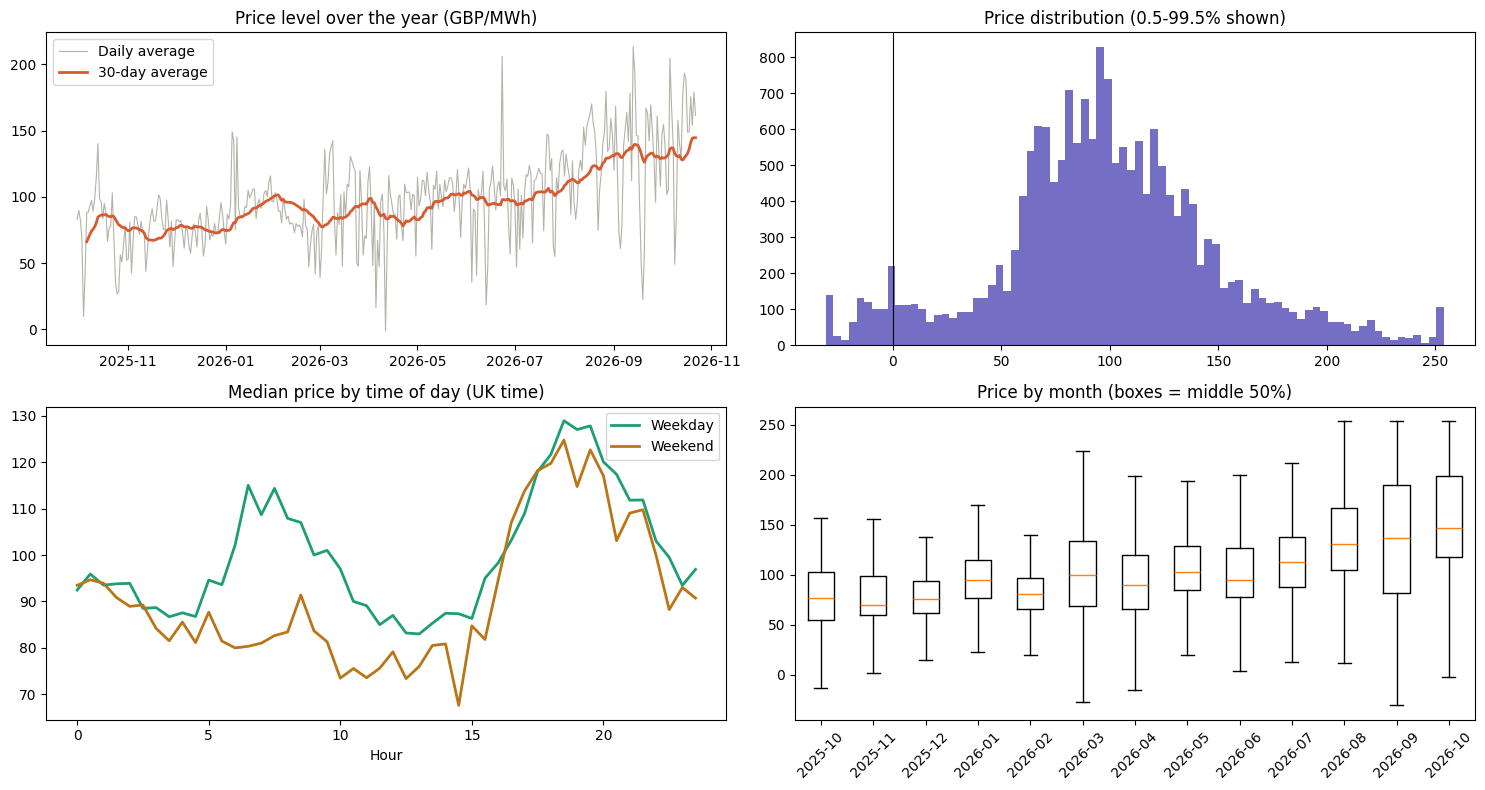

FINDINGS
- Most expensive time (weekdays): 18.5h at GBP129; cheapest: 13.0h at GBP83. Daily spread = GBP46/MWh: the battery's core opportunity.
- Weekends are GBP9/MWh cheaper on average.
- 4.3% of half-hours had NEGATIVE prices (paid to charge); 0.2% spiked above GBP300.
- Monthly median ranged from GBP70 (2025-11) to GBP147 (2026-10): the price LEVEL moves a lot, so models must adapt.


In [7]:
# ===== 6. EDA 1: how the imbalance price behaves =====
e = clean.dropna(subset=["price"]).copy()
loc = e.startTime.dt.tz_convert("Europe/London")
e["hour"] = loc.dt.hour + loc.dt.minute / 60
e["weekend"] = loc.dt.weekday >= 5
e["month"] = loc.dt.to_period("M").astype(str)
lo_, hi_ = e.price.quantile([0.005, 0.995])

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
daily = e.set_index("startTime").price.resample("D").mean()
ax[0, 0].plot(daily.index, daily, color="#B4B2A9", lw=0.8, label="Daily average")
ax[0, 0].plot(daily.index, daily.rolling(30, min_periods=7).mean(), color="#D85A30", lw=2, label="30-day average")
ax[0, 0].set_title("Price level over the year (GBP/MWh)"); ax[0, 0].legend()
ax[0, 1].hist(e.price.clip(lo_, hi_), bins=80, color="#534AB7", alpha=0.8)
ax[0, 1].axvline(0, color="black", lw=0.8); ax[0, 1].set_title("Price distribution (0.5-99.5% shown)")
prof = e.groupby(["weekend", "hour"]).price.median().unstack(0)
ax[1, 0].plot(prof.index, prof[False], color="#1D9E75", lw=2, label="Weekday")
ax[1, 0].plot(prof.index, prof[True], color="#BA7517", lw=2, label="Weekend")
ax[1, 0].set_title("Median price by time of day (UK time)"); ax[1, 0].set_xlabel("Hour"); ax[1, 0].legend()
months = sorted(e.month.unique())
ax[1, 1].boxplot([e.loc[e.month == m, "price"].clip(lo_, hi_) for m in months], showfliers=False)
ax[1, 1].set_xticks(range(1, len(months) + 1)); ax[1, 1].set_xticklabels(months)
ax[1, 1].set_title("Price by month (boxes = middle 50%)"); ax[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

wd = prof[False]
print("FINDINGS")
print(f"- Most expensive time (weekdays): {wd.idxmax():04.1f}h at GBP{wd.max():,.0f}; cheapest: {wd.idxmin():04.1f}h "
      f"at GBP{wd.min():,.0f}. Daily spread = GBP{wd.max() - wd.min():,.0f}/MWh: the battery's core opportunity.")
print(f"- Weekends are GBP{(prof[False] - prof[True]).mean():,.0f}/MWh cheaper on average.")
print(f"- {(e.price < 0).mean():.1%} of half-hours had NEGATIVE prices (paid to charge); "
      f"{(e.price > 300).mean():.1%} spiked above GBP300.")
mm = e.groupby("month").price.median()
print(f"- Monthly median ranged from GBP{mm.min():,.0f} ({mm.idxmin()}) to GBP{mm.max():,.0f} ({mm.idxmax()}): "
      "the price LEVEL moves a lot, so models must adapt.")

**What this does:** What drives the price: shortage vs surplus on the grid, demand left over after wind, correlations, and how much recent prices predict the next one.

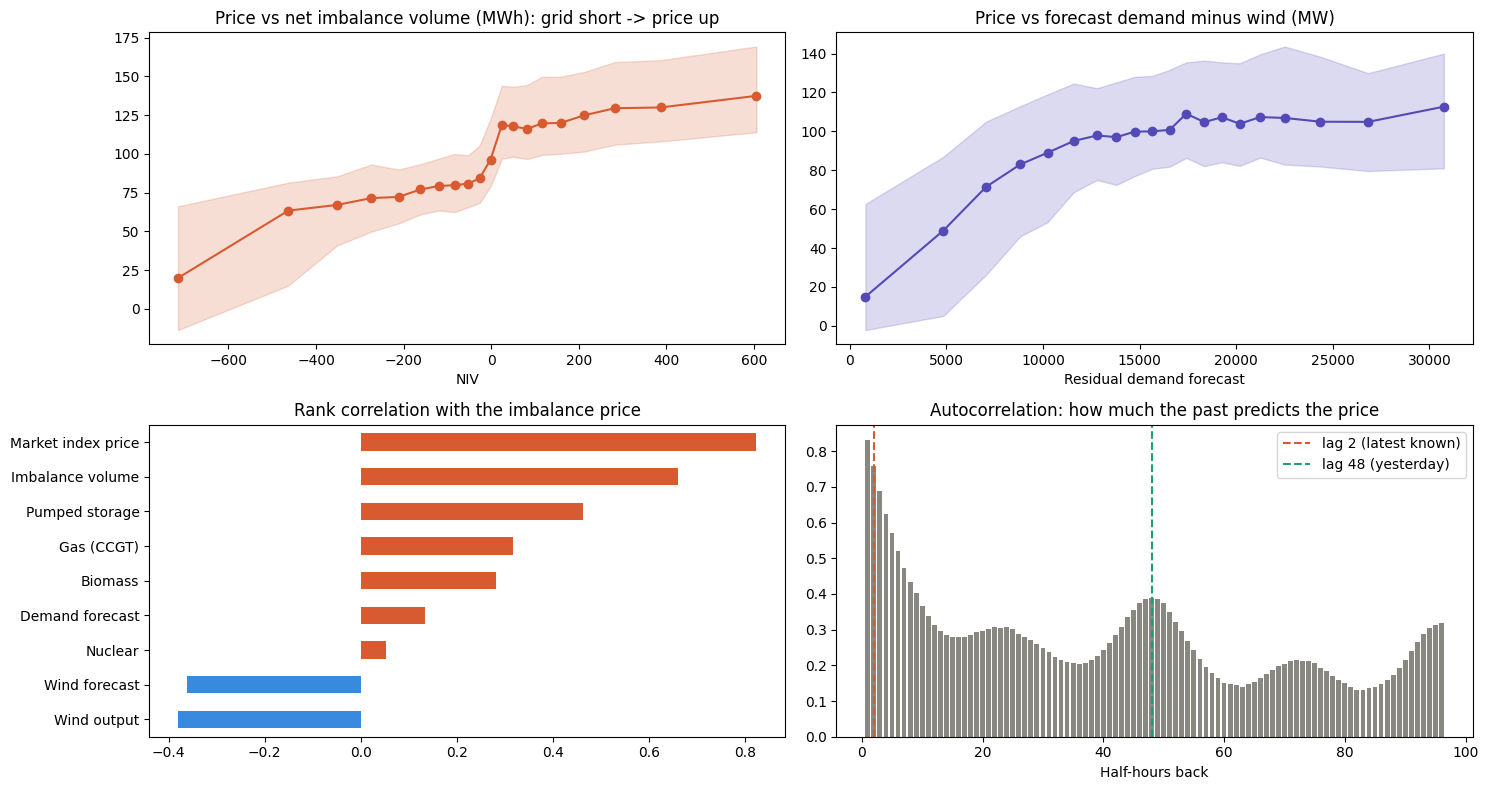

FINDINGS
- Price vs imbalance volume correlation: +0.66 (shortage = higher price; this is the core mechanism).
- Price vs (demand - wind) forecast: +0.35 (less wind left to cover demand = more gas = higher price).
- Strongest single driver: Market index price (+0.82).
- Autocorrelation at lag 2 = 0.76, at lag 48 = 0.39: recent prices carry strong information, yesterday's much less.


In [8]:
# ===== 7. EDA 2: what drives the price =====
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
def binned(x, y, bins=20):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    d["b"] = pd.qcut(d.x, bins, duplicates="drop")
    g = d.groupby("b", observed=True).agg(x=("x", "median"), y=("y", "median"),
                                          lo=("y", lambda s: s.quantile(0.25)), hi=("y", lambda s: s.quantile(0.75)))
    return g
findings = []
if "niv" in e and e.niv.notna().any():
    g = binned(e.niv, e.price)
    ax[0, 0].fill_between(g.x, g.lo, g.hi, alpha=0.2, color="#D85A30"); ax[0, 0].plot(g.x, g.y, "o-", color="#D85A30")
    ax[0, 0].set_title("Price vs net imbalance volume (MWh): grid short -> price up"); ax[0, 0].set_xlabel("NIV")
    findings.append(f"- Price vs imbalance volume correlation: {e.price.corr(e.niv, method='spearman'):+.2f} "
                    "(shortage = higher price; this is the core mechanism).")
if {"demand_fc", "wind_fc"} <= set(e.columns) and e.wind_fc.notna().any():
    resid = e.demand_fc - e.wind_fc
    g = binned(resid, e.price)
    ax[0, 1].fill_between(g.x, g.lo, g.hi, alpha=0.2, color="#534AB7"); ax[0, 1].plot(g.x, g.y, "o-", color="#534AB7")
    ax[0, 1].set_title("Price vs forecast demand minus wind (MW)"); ax[0, 1].set_xlabel("Residual demand forecast")
    findings.append(f"- Price vs (demand - wind) forecast: {e.price.corr(resid, method='spearman'):+.2f} "
                    "(less wind left to cover demand = more gas = higher price).")
cand = {"Market index price": "market_price", "Wind output": "gen_WIND", "Gas (CCGT)": "gen_CCGT",
        "Nuclear": "gen_NUCLEAR", "Demand forecast": "demand_fc", "Wind forecast": "wind_fc",
        "Imbalance volume": "niv", "Biomass": "gen_BIOMASS", "Pumped storage": "gen_PS"}
corr = pd.Series({k: e.price.corr(e[v], method="spearman") for k, v in cand.items() if v in e}).dropna().sort_values()
corr.plot.barh(ax=ax[1, 0], color=np.where(corr > 0, "#D85A30", "#378ADD"))
ax[1, 0].set_title("Rank correlation with the imbalance price")
lags = range(1, 97)
ac = [e.set_index("startTime").price.asfreq("30min").autocorr(l) for l in lags]
ax[1, 1].bar(list(lags), ac, color="#888780"); ax[1, 1].axvline(2, color="#D85A30", ls="--", label="lag 2 (latest known)")
ax[1, 1].axvline(48, color="#1D9E75", ls="--", label="lag 48 (yesterday)")
ax[1, 1].set_title("Autocorrelation: how much the past predicts the price"); ax[1, 1].set_xlabel("Half-hours back")
ax[1, 1].legend(); plt.tight_layout(); plt.show()
print("FINDINGS"); print("\n".join(findings))
print(f"- Strongest single driver: {corr.abs().idxmax()} ({corr[corr.abs().idxmax()]:+.2f}).")
print(f"- Autocorrelation at lag 2 = {ac[1]:.2f}, at lag 48 = {ac[47]:.2f}: recent prices carry strong information, "
      "yesterday's much less.")

**What this does:** Checks whether the market changed over time. If test months look different from training months, a model trained once will be biased, which motivates the fixes used below.

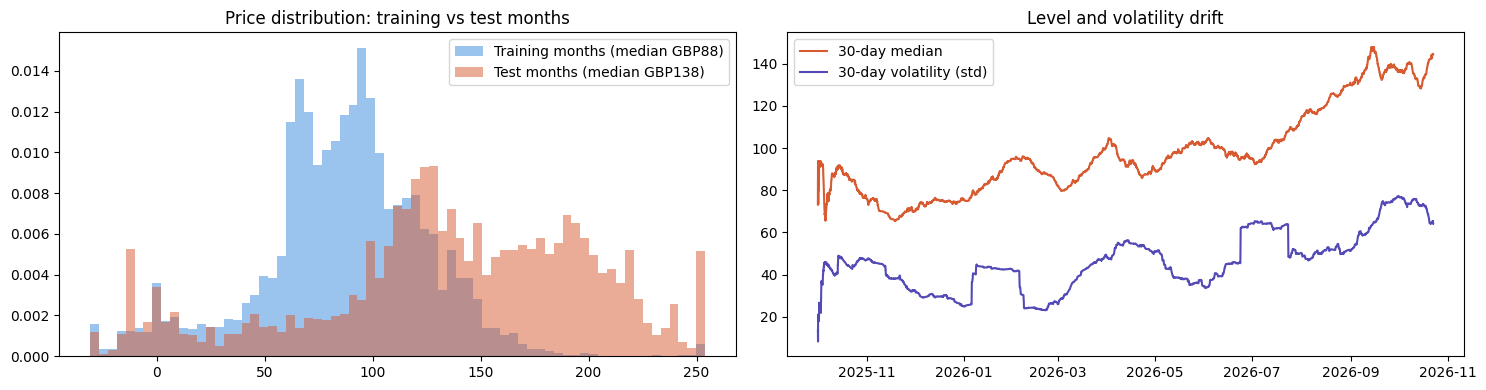

FINDINGS
- Test-month prices are GBP+50/MWh vs training months (median), volatility 1.61x.
- A model trained once on old months under-predicts after a shift like this (seen in v1: only 34% of prices fell below its median). Fixes used below:
  1) predict the CHANGE vs the latest market price (adapts to level automatically)
  2) retrain every two weeks on all data so far (walk-forward)
  3) build uncertainty ranges from the most recent 30 days of real forecast errors


In [9]:
# ===== 8. EDA 3: did the market change over time? (explains model bias) =====
k1, k2 = int(len(e) * 0.65), int(len(e) * 0.80)
early, late = e.iloc[:k1], e.iloc[k2:]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
bins = np.linspace(lo_, hi_, 70)
ax[0].hist(early.price.clip(lo_, hi_), bins=bins, density=True, alpha=0.5, color="#378ADD",
           label=f"Training months (median GBP{early.price.median():.0f})")
ax[0].hist(late.price.clip(lo_, hi_), bins=bins, density=True, alpha=0.5, color="#D85A30",
           label=f"Test months (median GBP{late.price.median():.0f})")
ax[0].legend(); ax[0].set_title("Price distribution: training vs test months")
roll = e.set_index("startTime").price.rolling("30D")
ax[1].plot(roll.median().index, roll.median(), color="#D85A30", label="30-day median")
ax[1].plot(roll.std().index, roll.std(), color="#534AB7", label="30-day volatility (std)")
ax[1].legend(); ax[1].set_title("Level and volatility drift"); plt.tight_layout(); plt.show()
shift = late.price.median() - early.price.median()
print("FINDINGS")
print(f"- Test-month prices are GBP{shift:+,.0f}/MWh vs training months (median), "
      f"volatility {late.price.std() / early.price.std():.2f}x.")
print("- A model trained once on old months under-predicts after a shift like this (seen in v1: only 34% of prices "
      "fell below its median). Fixes used below:")
print("  1) predict the CHANGE vs the latest market price (adapts to level automatically)")
print("  2) retrain every two weeks on all data so far (walk-forward)")
print("  3) build uncertainty ranges from the most recent 30 days of real forecast errors")

**What this does:** Turns the cleaned data into model inputs. Rule: a decision at the start of a half-hour may only use prices already published (2 periods back), the latest fuel mix and market price, and forecasts published in advance.

In [10]:
# ===== 9. Leak-free features =====
# Decision for period P is made at the START of P. Known then:
#   * imbalance prices up to P-2 (P-1's price is published ~15 min after P-1 ends)
#   * fuel mix and market price for P-1 (near real time)
#   * wind / demand forecasts for P published >= 1 hour earlier
def col(df, name):
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)

def build_features(raw):
    df = raw.sort_values("startTime").reset_index(drop=True).copy()
    local = df["startTime"].dt.tz_convert("Europe/London")
    gen = [c for c in df.columns if c.startswith("gen_")]
    df["gas"]     = col(df, "gen_CCGT").fillna(0) + col(df, "gen_OCGT").fillna(0)
    df["imports"] = df[[c for c in gen if c.startswith("gen_INT")]].sum(axis=1, min_count=1) if gen else np.nan
    df["total_gen"] = df[gen].sum(axis=1, min_count=1) if gen else np.nan
    df["wind_act"]  = col(df, "gen_WIND")

    f = pd.DataFrame({"startTime": df["startTime"], "price": col(df, "price")})
    p = df["price"]
    for k in (2, 3, 4, 6, 48, 336):                      # 48 = same time yesterday, 336 = last week
        f[f"price_lag{k}"] = p.shift(k)
    known = p.shift(2)
    f["price_mean_6"]  = known.rolling(6, min_periods=3).mean()
    f["price_std_6"]   = known.rolling(6, min_periods=3).std()
    f["price_max_48"]  = known.rolling(48, min_periods=12).max()
    f["ref_price"]     = known.rolling(336, min_periods=48).median()   # 7-day typical price
    # typical price at this time of day over the last 7 days (all already published)
    f["tod_profile"]   = pd.concat([p.shift(48 * k) for k in range(1, 8)], axis=1).median(axis=1)
    # smoother 28-day daily shape used for planning ahead (still only published prices)
    f["profile28"] = (pd.concat([p.shift(48 * k) for k in range(1, 29)], axis=1).median(axis=1)
                        .rolling(5, center=True, min_periods=1).median())
    f["price_vs_ref"]  = f["price_lag2"] - f["ref_price"]
    f["niv_lag2"]      = col(df, "niv").shift(2)
    f["niv_lag3"]      = col(df, "niv").shift(3)
    f["mkt_lag1"]      = col(df, "market_price").shift(1)
    f["mkt_lag2"]      = col(df, "market_price").shift(2)
    f["mkt_minus_ref"] = f["mkt_lag1"] - f["ref_price"]
    f["wind_act_lag1"] = df["wind_act"].shift(1)
    f["wind_fc"]       = col(df, "wind_fc")
    f["wind_err_lag1"] = df["wind_act"].shift(1) - col(df, "wind_fc").shift(1)   # +: more wind than expected
    f["wind_ramp_fc"]  = col(df, "wind_fc") - df["wind_act"].shift(1)            # expected change in wind
    f["demand_fc"]     = col(df, "demand_fc")
    f["residual_fc"]   = col(df, "demand_fc") - col(df, "wind_fc")                      # demand left for gas etc.
    f["gas_lag1"]      = df["gas"].shift(1)
    f["gas_share_lag1"] = (df["gas"] / df["total_gen"]).shift(1)
    f["nuclear_lag1"]  = col(df, "gen_NUCLEAR").shift(1)
    f["imports_lag1"]  = df["imports"].shift(1)
    f["gas_ramp_lag1"] = df["gas"].shift(1) - df["gas"].shift(3)
    hr = local.dt.hour + local.dt.minute / 60
    f["hour"] = hr
    f["hour_sin"], f["hour_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)
    f["weekday"] = local.dt.weekday
    f["weekend"] = (local.dt.weekday >= 5).astype(int)
    f["month"]   = local.dt.month
    f["is_peak"] = ((hr >= 16) & (hr < 19.5)).astype(int)
    # latest market price: the anchor for change models. Live, the newest prices may not be published yet,
    # so fall back to the most recent known value (forward-fill uses only the past)
    f["base"] = f["mkt_lag1"].fillna(f["price_lag2"]).ffill()
    # day-ahead forecasts (published >= 24h before each half-hour): inputs to the multi-horizon model
    f["wind_fc_da"]   = col(df, "wind_fc_da")
    f["demand_fc_da"] = col(df, "demand_fc_da")
    f["resid_da"]     = f["demand_fc_da"] - f["wind_fc_da"]
    f["local_date"] = local.dt.date
    return f

feat = build_features(clean)
FEATURES = [c for c in feat.columns
            if c not in ("startTime", "price", "local_date", "profile28", "base", "wind_fc_da", "demand_fc_da", "resid_da") and feat[c].notna().mean() > 0.5]
data = feat.dropna(subset=["price", "price_lag2", "ref_price", "profile28"]).reset_index(drop=True)
print(f"{len(data):,} usable half-hours, {len(FEATURES)} features:")
print(FEATURES)

18,527 usable half-hours, 35 features:
['price_lag2', 'price_lag3', 'price_lag4', 'price_lag6', 'price_lag48', 'price_lag336', 'price_mean_6', 'price_std_6', 'price_max_48', 'ref_price', 'tod_profile', 'price_vs_ref', 'niv_lag2', 'niv_lag3', 'mkt_lag1', 'mkt_lag2', 'mkt_minus_ref', 'wind_act_lag1', 'wind_fc', 'wind_err_lag1', 'wind_ramp_fc', 'demand_fc', 'residual_fc', 'gas_lag1', 'gas_share_lag1', 'nuclear_lag1', 'imports_lag1', 'gas_ramp_lag1', 'hour', 'hour_sin', 'hour_cos', 'weekday', 'weekend', 'month', 'is_peak']


**What this does:** The decision engine. `step` applies one charge/discharge with real limits and losses. `lp_schedule` is a small linear program that finds the most profitable charge/discharge plan over the next 22 hours. `run_mpc` repeats this every half-hour, acting only on the first step (re-planning with fresh information), which is how real battery operators work.

In [11]:
# ===== 10. Battery simulator, decision engine and benchmarks =====
def step(soc, action, price):
    # action in [-1, 1]: + = discharge, - = charge (fraction of max power)
    if action > 1e-9:
        out = min(action * E_STEP, (soc - SOC_MIN) * ETA)
        return soc - out / ETA, 0.0, out, out * price - DEG_COST * out
    if action < -1e-9:
        inn = min(-action * E_STEP, (SOC_MAX - soc) / ETA)
        return soc + inn * ETA, inn, 0.0, -inn * price
    return soc, 0.0, 0.0, 0.0

def lp_schedule(soc0, p_buy, p_sell, end_soc=SOC_START, end_equal=False):
    # Best charge/discharge plan over the horizon for given buy/sell price paths (linear program)
    n = len(p_buy)
    c = np.concatenate([p_buy, -p_sell + DEG_COST, np.zeros(n)])
    A = np.zeros((n, 3 * n)); b = np.zeros(n)
    idx = np.arange(n)
    A[idx, idx] = -ETA; A[idx, n + idx] = 1 / ETA; A[idx, 2 * n + idx] = 1
    A[idx[1:], 2 * n + idx[1:] - 1] = -1; b[0] = soc0
    bounds = [(0, E_STEP)] * (2 * n) + [(SOC_MIN, SOC_MAX)] * n
    term = np.zeros((1, 3 * n)); term[0, -1] = 1
    if end_equal:
        res = linprog(c, A_eq=np.vstack([A, term]), b_eq=np.append(b, end_soc), bounds=bounds, method="highs")
    else:
        res = linprog(c, A_eq=A, b_eq=b, A_ub=-term, b_ub=[-min(end_soc, SOC_MAX)], bounds=bounds, method="highs")
    if not res.success: return None, None
    return res.x[:n], res.x[n:2 * n]

HORIZON = 44   # plan 22 hours ahead; every price used is already published or forecast at decision time

def run_mpc(df, p1, kappa=0.0, soc=SOC_START, future=None):
    # Rolling optimisation: every half-hour, plan the next 22h, do only the first step, then re-plan.
    #   step 1 price  = p1 (our forecast for the coming half-hour)
    #   later steps   = typical price for that time of day (28-day median, already published)
    #   kappa         = trading hurdle (GBP/MWh) so the plan ignores spreads smaller than forecast noise
    #   future        = optional (rows x 43) forecast for steps 2..44, replacing the typical shape
    actual, prof = df["price"].values, df["profile28"].values
    log = []
    for i in range(len(df)):
        fut = prof[i + 1:i + HORIZON]
        if len(fut) < HORIZON - 1:
            fut = np.concatenate([fut, np.full(HORIZON - 1 - len(fut), prof[i])])
        if future is not None:          # optional forecast for the later steps (multi-horizon model)
            fz = future[i]
            fut = np.where(np.isfinite(fz), fz, fut)
        path = np.concatenate([[p1[i]], fut])
        ch, dis = lp_schedule(soc, path + kappa, path - kappa)
        a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP
        soc, e_in, e_out, pnl = step(soc, a, actual[i])
        log.append((df["startTime"].iloc[i], a, soc, e_in, e_out, pnl))
    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])

def blend(df, forecast, alpha):
    # Trust the forecast in proportion to its proven skill: alpha=1 uses it fully, 0 ignores it
    prof = df["profile28"].values
    return prof + alpha * (np.asarray(forecast) - prof)

def run_fixed(df, soc=SOC_START):
    # What many simple sites do: charge overnight, discharge at the evening peak
    log = []
    for t, h, p in zip(df["startTime"], df["hour"], df["price"]):
        a = -1.0 if 1 <= h < 4.5 else 1.0 if 16.5 <= h < 19.5 else 0.0
        soc, e_in, e_out, pnl = step(soc, a, p)
        log.append((t, a, soc, e_in, e_out, pnl))
    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])

def perfect_hindsight(df, soc0=SOC_START):
    # Upper bound: the best possible schedule for each day if every price were known in advance
    total, out = 0.0, []
    for _, d in df.groupby("local_date", sort=True):
        p = d["price"].values
        ch, dis = lp_schedule(soc0, p, p, end_soc=soc0, end_equal=True)
        if ch is None: continue
        pnl = p * dis - p * ch - DEG_COST * dis
        total += pnl.sum()
        out.append(pd.DataFrame({"startTime": d["startTime"].values, "pnl": pnl}))
    return total, pd.concat(out) if out else pd.DataFrame(columns=["startTime", "pnl"])

> **Tell the judges (data):** real Elexon data, one row per half-hour; no look-ahead anywhere (each forecast is
> used only if it was published early enough); gaps filled only from the past; price spikes kept because they are
> real; all times in UTC, so clock changes (like tonight's) are handled correctly.

## Model comparison

Every candidate is retrained **every two weeks on all data available at that time** (walk-forward), exactly as it would run live.
Candidates are compared on the **validation months** by forecast error, by whether they get the direction right
(above or below the usual price for that time of day, which is what drives trading), and most importantly by **the profit the battery
makes when the optimiser uses that forecast**. The best one by validation profit is chosen; test months are only used once, at the end.

**What this does:** Four forecasters for the next half-hour: two simple baselines and two LightGBM models (one predicts the price, one predicts the change from the latest market price). Optional small hyperparameter search on validation months. Each model is retrained every two weeks on all data available at that time (walk-forward), exactly as it would run live.

In [12]:
# ===== 11. Candidate models, walk-forward retraining =====
n = len(data)
i_val, i_test = int(n * 0.65), int(n * 0.80)
CHUNK, GAP = 672, 2           # retrain every 2 weeks; skip the 2 newest rows (their prices aren't published yet)
WF_START = max(i_val - 2 * CHUNK, 2000)
val, test = data.iloc[i_val:i_test], data.iloc[i_test:]
print(f"validate {val.startTime.min():%d %b %Y} -> {val.startTime.max():%d %b %Y} ({len(val):,})   "
      f"test {test.startTime.min():%d %b %Y} -> {test.startTime.max():%d %b %Y} ({len(test):,})")

LGB_PARAMS = dict(n_estimators=500, learning_rate=0.04, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

def fit_cand(kind, df):
    # the two simple baselines need no training
    if kind in ("persist", "market"): return None
    # LightGBM with "l1" loss = predicts the median, so rare price spikes don't dominate training
    if kind == "lgb_price":                      # learns the price directly
        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price)
    if kind == "lgb_change":                     # learns the CHANGE from the latest market price (adapts to price level)
        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price - df.base)
    raise ValueError(kind)

def predict_cand(kind, obj, df):
    if kind == "persist":    return df.price_lag2.values                     # "price stays as last published"
    if kind == "market":     return df.base.values                           # "price = latest market price"
    if kind == "lgb_price":  return obj.predict(df[FEATURES])
    if kind == "lgb_change": return df.base.values + obj.predict(df[FEATURES])
    raise ValueError(kind)

CANDIDATES = {
    "Persistence (latest known price)": "persist",
    "Market index (last half-hour)":    "market",
    "LightGBM (price)":                 "lgb_price",
    "LightGBM (change vs market)":      "lgb_change",
}

def walk_forward(kind):
    out = np.full(n, np.nan)
    for s in range(WF_START, n, CHUNK):
        e_ = min(s + CHUNK, n)
        obj = fit_cand(kind, data.iloc[:s - GAP])
        out[s:e_] = predict_cand(kind, obj, data.iloc[s:e_])
    return out

LGB_GRID = [   # small, sensible search space (the second entry is the default)
    dict(num_leaves=15,  learning_rate=0.05, n_estimators=400, min_child_samples=50),
    dict(num_leaves=31,  learning_rate=0.04, n_estimators=500, min_child_samples=50),
    dict(num_leaves=63,  learning_rate=0.03, n_estimators=600, min_child_samples=100),
    dict(num_leaves=31,  learning_rate=0.08, n_estimators=250, min_child_samples=20),
    dict(num_leaves=127, learning_rate=0.03, n_estimators=500, min_child_samples=200),
    dict(num_leaves=15,  learning_rate=0.03, n_estimators=900, min_child_samples=100),
    dict(num_leaves=31,  learning_rate=0.03, n_estimators=800, min_child_samples=100, reg_lambda=5.0),
    dict(num_leaves=63,  learning_rate=0.05, n_estimators=300, min_child_samples=50, colsample_bytree=0.5),
]
if TUNE_MODELS:
    t0 = time.time()
    tr_, va_ = data.iloc[:i_val - GAP], data.iloc[i_val:i_test]
    maes = []
    for g_ in LGB_GRID:
        m_ = lgb.LGBMRegressor(objective="l1", **{**LGB_PARAMS, **g_}).fit(tr_[FEATURES], tr_.price - tr_.base)
        maes.append(np.mean(np.abs(va_.price - (va_.base + m_.predict(va_[FEATURES])))))
    tune_tab = pd.DataFrame(LGB_GRID).assign(**{"Validation MAE": maes}).sort_values("Validation MAE")
    print("Hyperparameter search for the next-half-hour LightGBM (trained on training months, scored on validation):")
    print(tune_tab.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:g}"))
    best_i = int(np.argmin(maes))
    LGB_PARAMS = {**LGB_PARAMS, **LGB_GRID[best_i]}
    print(f"-> chosen setting #{best_i + 1}: validation error GBP{maes[best_i]:.2f} vs GBP{maes[1]:.2f} with defaults "
          f"({time.time() - t0:.0f}s)\n")

t0 = time.time(); WF = {}
for name, kind in CANDIDATES.items():
    WF[name] = walk_forward(kind)
    print(f"   {name:36s} done ({time.time() - t0:.0f}s)")

def band(q50, window=1440):
    # 80% range from the last 30 days of REAL out-of-sample errors (only errors already known)
    res = pd.Series(data.price.values - q50).shift(GAP)
    lo = res.rolling(window, min_periods=200).quantile(0.10).values
    hi = res.rolling(window, min_periods=200).quantile(0.90).values
    return pd.DataFrame({"q10": q50 + lo, "q50": q50, "q90": q50 + hi}, index=data.index)

validate 09 Jun 2026 -> 06 Aug 2026 (2,779)   test 06 Aug 2026 -> 22 Oct 2026 (3,706)
Hyperparameter search for the next-half-hour LightGBM (trained on training months, scored on validation):
 num_leaves  learning_rate  n_estimators  min_child_samples  reg_lambda  colsample_bytree  Validation MAE
        127           0.03           500                200           -                 -         22.1404
         15           0.03           900                100           -                 -         22.1971
         31           0.03           800                100           5                 -         22.2219
         15           0.05           400                 50           -                 -         22.2377
         63           0.03           600                100           -                 -         22.2629
         63           0.05           300                 50           -               0.5         22.2656
         31           0.04           500                 50       

**What this does:** Scores each forecaster on the validation months by accuracy, by direction (above or below the usual price) and, most importantly, by the profit the battery makes using it. The best by profit is chosen.

(38s)

                           Model  MAE RMSE Direction right Validation profit (GBP)
Persistence (latest known price) 25.2 39.5             74%                 308,512
                LightGBM (price) 23.0 39.7             75%                 282,602
   Market index (last half-hour) 24.1 33.3             74%                 273,415
     LightGBM (change vs market) 22.1 32.1             76%                 269,495

CHOSEN: Persistence (latest known price)  (highest validation profit)
Note: the most ACCURATE model was LightGBM (change vs market); we choose by profit because the decision is what pays.


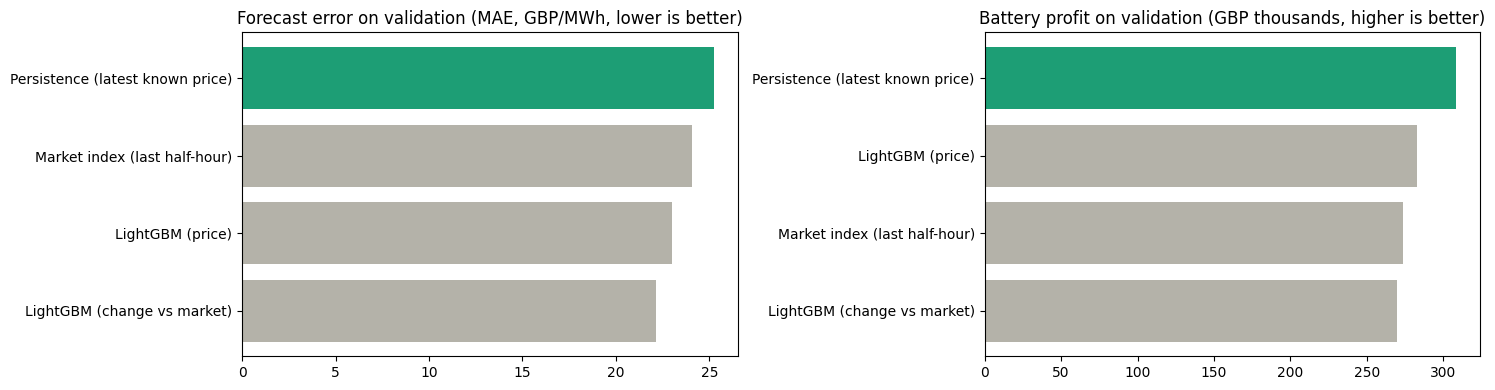

Chosen model's 80% range on validation holds 79% of actual prices (below median: 49%, ideal 50%).


In [13]:
# ===== 12. Compare on VALIDATION months and choose the best by profit =====
t0 = time.time()
rows = []
yv = val.price.values
for name, q50 in WF.items():
    pv = q50[i_val:i_test]
    prof = val.tod_profile.values
    ok = ~np.isnan(prof)
    direction = (np.nan if np.allclose(pv[ok], prof[ok], equal_nan=True)     # the profile itself has no direction
                 else np.mean(np.sign(pv[ok] - prof[ok]) == np.sign(yv[ok] - prof[ok])))
    profit = run_mpc(val, blend(val, pv, 0.5), 5.0)["pnl"].sum()
    rows.append({"Model": name, "MAE": np.mean(np.abs(yv - pv)), "RMSE": np.sqrt(np.mean((yv - pv) ** 2)),
                 "Direction right": direction, "Validation profit (GBP)": profit})
comp = pd.DataFrame(rows).sort_values("Validation profit (GBP)", ascending=False).reset_index(drop=True)
BEST = comp.loc[0, "Model"]; BEST_KIND = CANDIDATES[BEST]
print(f"({time.time() - t0:.0f}s)\n")
print(comp.to_string(index=False, na_rep="n/a", formatters={"MAE": "{:.1f}".format, "RMSE": "{:.1f}".format,
      "Direction right": lambda v: "n/a" if pd.isna(v) else f"{v:.0%}", "Validation profit (GBP)": "{:,.0f}".format}))
print(f"\nCHOSEN: {BEST}  (highest validation profit)")
best_mae = comp.sort_values("MAE").iloc[0]
if best_mae.Model != BEST:
    print(f"Note: the most ACCURATE model was {best_mae.Model}; we choose by profit because the decision is what pays.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
c2 = comp.sort_values("MAE")
ax[0].barh(c2.Model, c2.MAE, color=["#1D9E75" if m == BEST else "#B4B2A9" for m in c2.Model])
ax[0].set_title("Forecast error on validation (MAE, GBP/MWh, lower is better)")
c3 = comp.sort_values("Validation profit (GBP)")
ax[1].barh(c3.Model, c3["Validation profit (GBP)"] / 1000, color=["#1D9E75" if m == BEST else "#B4B2A9" for m in c3.Model])
ax[1].set_title("Battery profit on validation (GBP thousands, higher is better)")
plt.tight_layout(); plt.show()

BANDS = {name: band(q50) for name, q50 in WF.items()}
pred_all = BANDS[BEST]
pred_val, pred_test = pred_all.iloc[i_val:i_test], pred_all.iloc[i_test:]
cv = np.mean((yv >= pred_val.q10) & (yv <= pred_val.q90))
print(f"Chosen model's 80% range on validation holds {cv:.0%} of actual prices "
      f"(below median: {np.mean(yv < pred_val.q50):.0%}, ideal 50%).")

## Multi-horizon forecast: the whole 22-hour plan from machine learning

The optimiser plans 22 hours ahead. Until now only the coming half-hour came from a model; the other 43 steps used the
28-day typical shape. Here a second LightGBM model forecasts **every one of the next 43 half-hours**, using the official
day-ahead **wind and demand forecasts** (published at least 24 hours before each half-hour, so they were genuinely
available at decision time), the current state of the market, and the typical shape. It is retrained every 4 weeks (walk-forward).

**What this does:** A second LightGBM model forecasts each of the next 43 half-hours (22 hours) using the official day-ahead wind and demand forecasts. One training row per (decision time, hours ahead) pair. The chart compares its error with the typical daily shape at every horizon.

Hyperparameter search for the multi-horizon model (scored on validation months):
 num_leaves  learning_rate  n_estimators  min_child_samples  colsample_bytree  Validation MAE
         63           0.03           600                100               0.6         31.9591
         63           0.05           300                100                 -         32.0423
        127           0.05           300                200                 -         32.0655
        255           0.05           250                400                 -         32.1103
         31           0.05           400                200                 -         32.1216
-> chosen setting #4: GBP31.96 vs GBP32.04 with defaults (46s)

Multi-horizon walk-forward done (97s)


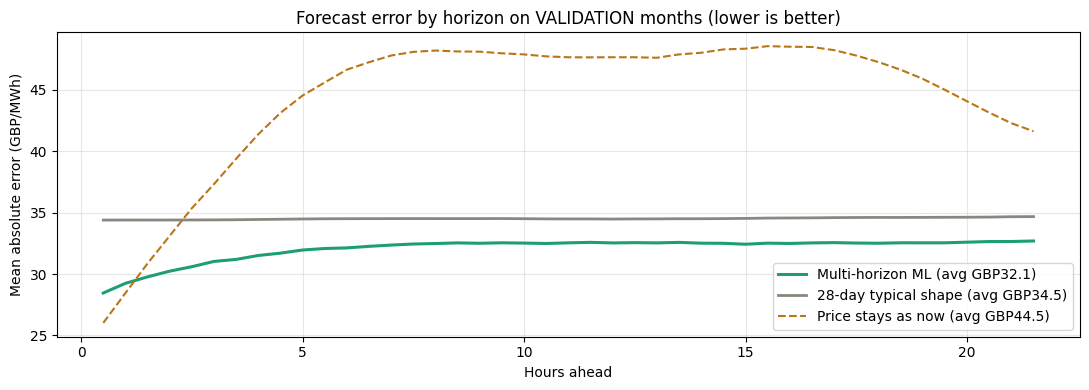

Across the 22-hour plan, the ML forecast is 7% more accurate than the 28-day shape and 28% more accurate than 'price stays as now'.


In [14]:
# ===== 12b. Multi-horizon forecast for the next 43 half-hours =====
HZ = HORIZON - 1
NOW_COLS = ["price_lag2", "price_mean_6", "price_std_6", "price_max_48", "ref_price", "niv_lag2",
            "wind_err_lag1", "wind_act_lag1", "gas_lag1", "mkt_lag1"]                     # known at decision time
AT_COLS = ["hour", "weekday", "weekend", "month", "is_peak", "profile28", "tod_profile", "price_lag48",
           "price_lag336", "wind_fc_da", "demand_fc_da", "resid_da"]                       # describe the target half-hour
MH_KS_TRAIN = np.array([1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 28, 32, 38, 43])
MH_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=100,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

def arrays(f):
    return {c: pd.to_numeric(f[c], errors="coerce").values.astype(float) for c in f.columns
            if c not in ("startTime", "local_date")}

def mh_frame(FA, js, ks):
    # one row per (decision half-hour j, steps ahead k); target = price at j+k minus its typical value
    N = len(FA["price"])
    J = np.repeat(np.asarray(js), len(ks)); K = np.tile(np.asarray(ks), len(js))
    valid = (J + K) < N
    T = np.minimum(J + K, N - 1)
    nan = np.full(len(J), np.nan)
    X = {f"now_{c}": FA.get(c, nan)[J] if c in FA else nan for c in NOW_COLS}
    X.update({f"at_{c}": FA[c][T] if c in FA else nan for c in AT_COLS})
    X["k"] = K
    X["dev_now"] = FA["base"][J] - FA["profile28"][J]
    X["wind_da_change"] = (FA["wind_fc_da"][T] if "wind_fc_da" in FA else nan) - FA["wind_act_lag1"][J]
    y = FA["price"][T] - FA["profile28"][T]
    return pd.DataFrame(X), y, T, valid

def fit_mh(FA, train_js, cutoff_pos, params=None):
    X, y, T, valid = mh_frame(FA, train_js, MH_KS_TRAIN)
    ok = valid & (T <= cutoff_pos - 3) & np.isfinite(y)       # only targets already published at cutoff
    return lgb.LGBMRegressor(objective="l1", **(params or MH_PARAMS)).fit(X[ok], y[ok])

def predict_mh(model, FA, js):
    ks = np.arange(1, HZ + 1)
    X, _, T, valid = mh_frame(FA, js, ks)
    p = model.predict(X) + FA["profile28"][T]
    p[~valid] = np.nan
    return p.reshape(len(js), HZ)

FA_ALL = arrays(feat)
POS = pd.Index(feat.startTime).get_indexer(data.startTime)          # each decision row on the full timeline
KS = np.arange(1, HZ + 1)
FUT_IDX = np.minimum(POS[:, None] + KS[None, :], len(feat) - 1)
FUT_OK = (POS[:, None] + KS[None, :]) < len(feat)
ACT_FUT = np.where(FUT_OK, FA_ALL["price"][FUT_IDX], np.nan)         # what actually happened (for scoring only)
PROF_FUT = np.where(FUT_OK, FA_ALL["profile28"][FUT_IDX], np.nan)    # the 28-day typical shape (old plan)

MH_GRID = [
    dict(num_leaves=63, learning_rate=0.05, n_estimators=300, min_child_samples=100),   # default
    dict(num_leaves=31, learning_rate=0.05, n_estimators=400, min_child_samples=200),
    dict(num_leaves=127, learning_rate=0.05, n_estimators=300, min_child_samples=200),
    dict(num_leaves=63, learning_rate=0.03, n_estimators=600, min_child_samples=100, colsample_bytree=0.6),
    dict(num_leaves=255, learning_rate=0.05, n_estimators=250, min_child_samples=400),
]
if TUNE_MODELS:
    t0 = time.time()
    ev = np.arange(i_val, i_test, 4)                     # validation decisions (every 2 hours, all 43 steps)
    act = ACT_FUT[ev]; maes = []
    for g_ in MH_GRID:
        m_ = fit_mh(FA_ALL, POS[:i_val:2], POS[i_val], params={**MH_PARAMS, **g_})
        p_ = predict_mh(m_, FA_ALL, POS[ev]); ok_ = np.isfinite(act) & np.isfinite(p_)
        maes.append(np.mean(np.abs(act - p_)[ok_]))
    print("Hyperparameter search for the multi-horizon model (scored on validation months):")
    print(pd.DataFrame(MH_GRID).assign(**{"Validation MAE": maes}).sort_values("Validation MAE")
          .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:g}"))
    best_i = int(np.argmin(maes)); MH_PARAMS = {**MH_PARAMS, **MH_GRID[best_i]}
    print(f"-> chosen setting #{best_i + 1}: GBP{maes[best_i]:.2f} vs GBP{maes[0]:.2f} with defaults ({time.time() - t0:.0f}s)\n")

t0 = time.time()
MH_CHUNK = 1344                                                       # retrain every 4 weeks
MH = np.full((n, HZ), np.nan)
for s_ in range(WF_START, n, MH_CHUNK):
    e_ = min(s_ + MH_CHUNK, n)
    model_ = fit_mh(FA_ALL, POS[:s_:2], POS[s_])
    MH[s_:e_] = predict_mh(model_, FA_ALL, POS[s_:e_])
print(f"Multi-horizon walk-forward done ({time.time() - t0:.0f}s)")

def future_path(lo, hi, beta):
    # plan prices for steps 2..44: typical shape moved towards the ML forecast by `beta` (0 = old behaviour)
    prof, mh = PROF_FUT[lo:hi], MH[lo:hi]
    return np.where(np.isfinite(mh) & np.isfinite(prof), prof + beta * (mh - prof), prof)

def mae_by_k(pred, lo, hi):
    a = ACT_FUT[lo:hi]; m = np.isfinite(a) & np.isfinite(pred[lo:hi])
    return np.array([np.mean(np.abs(a[:, k] - pred[lo:hi, k])[m[:, k]]) for k in range(HZ)])

persist_fut = np.repeat(data.base.values[:, None], HZ, axis=1)        # "price stays as it is now"
mk_ml, mk_prof, mk_pers = (mae_by_k(x, i_val, i_test) for x in (MH, PROF_FUT, persist_fut))
fig, ax = plt.subplots(figsize=(11, 4))
hrs = KS / 2
ax.plot(hrs, mk_ml, color="#1D9E75", lw=2.2, label=f"Multi-horizon ML (avg GBP{np.nanmean(mk_ml):.1f})")
ax.plot(hrs, mk_prof, color="#888780", lw=2, label=f"28-day typical shape (avg GBP{np.nanmean(mk_prof):.1f})")
ax.plot(hrs, mk_pers, color="#BA7517", lw=1.5, ls="--", label=f"Price stays as now (avg GBP{np.nanmean(mk_pers):.1f})")
ax.set_xlabel("Hours ahead"); ax.set_ylabel("Mean absolute error (GBP/MWh)")
ax.set_title("Forecast error by horizon on VALIDATION months (lower is better)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Across the 22-hour plan, the ML forecast is {1 - np.nanmean(mk_ml) / np.nanmean(mk_prof):.0%} more accurate "
      f"than the 28-day shape and {1 - np.nanmean(mk_ml) / np.nanmean(mk_pers):.0%} more accurate than 'price stays as now'.")

**What this does:** Chooses three decision settings on validation months only: how much to trust the next-half-hour forecast, a small trading hurdle that ignores spreads smaller than forecast noise, and how strongly to use the multi-horizon forecast (0 = not at all is allowed).

In [15]:
# ===== 13. Tune on VALIDATION only: trust in the next-half-hour forecast, trading hurdle, multi-horizon strength =====
t0 = time.time()
SETTINGS = [(al, k) for al in (0.25, 0.5, 1.0) for k in (0.0, 5.0, 10.0)]
def tune(df, forecast, future=None):
    scores = {(al, k): run_mpc(df, blend(df, forecast, al), k, future=future)["pnl"].sum() for al, k in SETTINGS}
    best = max(scores, key=scores.get)
    return best, scores[best]
(ALPHA, KAPPA0), score0 = tune(val, pred_val.q50.values)                 # plan with the 28-day shape (old GridMind)
MKT = "Market index (last half-hour)"
(ALPHA_M, KAPPA_M), _ = tune(val, WF[MKT][i_val:i_test])

# Selection rule fixed in advance: use the multi-horizon forecast only if it earns more on VALIDATION
p1_val = blend(val, pred_val.q50.values, ALPHA)
beta_scores = {(b, k): run_mpc(val, p1_val, k, future=future_path(i_val, i_test, b))["pnl"].sum()
               for b in (0.25, 0.5, 0.75, 1.0) for k in (0.0, 5.0, 10.0)}
(BETA, KAPPA) = max(beta_scores, key=beta_scores.get)
if beta_scores[(BETA, KAPPA)] <= score0:
    BETA, KAPPA = 0.0, KAPPA0
print(f"Validation profit with 28-day shape: GBP{score0:,.0f} | best with multi-horizon ML: "
      f"GBP{max(beta_scores.values()):,.0f}")
print(f"CHOSEN: next-half-hour trust={ALPHA}, multi-horizon strength={BETA}, hurdle=GBP{KAPPA}/MWh "
      f"| market-index baseline: trust={ALPHA_M}, hurdle=GBP{KAPPA_M}")
print(f"({time.time() - t0:.0f}s)")

Validation profit with 28-day shape: GBP341,879 | best with multi-horizon ML: GBP358,240
CHOSEN: next-half-hour trust=0.25, multi-horizon strength=0.25, hurdle=GBP5.0/MWh | market-index baseline: trust=0.25, hurdle=GBP5.0
(286s)


**What this does:** The final exam on test months that no choice ever used. Compares GridMind with a fixed schedule, a market-price forecast with the same optimiser, GridMind without the multi-horizon model, and perfect hindsight. The transparency table shows every forecaster's test profit with the same settings.

In [16]:
# ===== 14. The honest backtest on unseen TEST months =====
t0 = time.time()
yt = test.price.values
acc = pd.DataFrame([{"Model": m, "Test MAE": np.mean(np.abs(yt - q[i_test:])),
                     "80% range holds": np.mean((yt >= BANDS[m].q10.values[i_test:]) & (yt <= BANDS[m].q90.values[i_test:]))}
                    for m, q in WF.items()]).sort_values("Test MAE")
print("Forecast accuracy on test months (all candidates, for transparency):")
print(acc.to_string(index=False, formatters={"Test MAE": "{:.1f}".format, "80% range holds": "{:.0%}".format}))

mt_ml, mt_prof = mae_by_k(MH, i_test, n), mae_by_k(PROF_FUT, i_test, n)
print(f"\nMulti-horizon forecast on test months: average error GBP{np.nanmean(mt_ml):.1f} "
      f"vs GBP{np.nanmean(mt_prof):.1f} for the 28-day shape")

FUT_TEST = future_path(i_test, n, BETA)
p1_test = blend(test, pred_test.q50.values, ALPHA)
NOMH = "GridMind, 28-day shape for the plan (no multi-horizon)"
GM = f"GridMind ({BEST} + multi-horizon ML)" if BETA > 0 else f"GridMind ({BEST})"
runs = {
    "Fixed schedule (charge night, sell 4:30-7:30pm)": run_fixed(test),
    "Market index forecast + same optimiser":          run_mpc(test, blend(test, WF[MKT][i_test:], ALPHA_M), KAPPA_M),
    NOMH:                                              run_mpc(test, p1_test, KAPPA0),
    GM:                                                run_mpc(test, p1_test, KAPPA, future=FUT_TEST),
}
ph_total, ph_log = perfect_hindsight(test)
days = test["local_date"].nunique()

def summary(name, log):
    daily = log.groupby(log.startTime.dt.tz_convert("Europe/London").dt.date)["pnl"].sum()
    return {"Strategy": name, "Profit (GBP)": log.pnl.sum(), "GBP/MW/year": log.pnl.sum() / P_MAX_MW / days * 365,
            "Cycles/day": log.e_out.sum() / ETA / (SOC_MAX - SOC_MIN) / days,
            "Worst day (GBP)": daily.min(), "Losing days": f"{(daily < 0).mean():.0%}"}

table = pd.DataFrame([summary(k, v) for k, v in runs.items()])
table.loc[len(table)] = {"Strategy": "Perfect hindsight (theoretical max)", "Profit (GBP)": ph_total,
                         "GBP/MW/year": ph_total / P_MAX_MW / days * 365}
table["% of max"] = (table["Profit (GBP)"] / ph_total * 100).round(1)
fixed_pnl = table.loc[0, "Profit (GBP)"]
table["vs fixed"] = [f"{(v / fixed_pnl - 1) * 100:+.0f}%" if fixed_pnl > 0 else "" for v in table["Profit (GBP)"]]
print(f"\nBattery backtest: {days} test days never used for any choice  ({time.time() - t0:.0f}s)\n")
print(table.round(1).to_string(index=False))

# Transparency: EVERY next-half-hour model through the same final optimiser settings (chosen on validation)
t0 = time.time()
trans = pd.DataFrame([{"Next-half-hour model": m,
                       "Test profit (GBP)": run_mpc(test, blend(test, q[i_test:], ALPHA), KAPPA, future=FUT_TEST)["pnl"].sum(),
                       "Chosen": "<- chosen on validation" if m == BEST else ""} for m, q in WF.items()])
print(f"\nTransparency: every model with the same optimiser on test months ({time.time() - t0:.0f}s)")
print(trans.sort_values("Test profit (GBP)", ascending=False).to_string(index=False,
      formatters={"Test profit (GBP)": "{:,.0f}".format}))

Forecast accuracy on test months (all candidates, for transparency):
                           Model Test MAE 80% range holds
     LightGBM (change vs market)     28.4             77%
                LightGBM (price)     29.3             77%
   Market index (last half-hour)     30.8             76%
Persistence (latest known price)     33.2             77%

Multi-horizon forecast on test months: average error GBP41.4 vs GBP47.8 for the 28-day shape

Battery backtest: 78 test days never used for any choice  (39s)

                                                      Strategy  Profit (GBP)  GBP/MW/year  Cycles/day  Worst day (GBP) Losing days  % of max vs fixed
               Fixed schedule (charge night, sell 4:30-7:30pm)      110594.3      10350.5         1.0         -11146.0         44%       6.8      +0%
                        Market index forecast + same optimiser      502070.4      46988.6         1.4          -5501.6         19%      30.9    +354%
        GridMind, 28-day shape 

**What this does:** Cumulative profit over the test months, and the most volatile day showing forecasts, decisions and battery level.

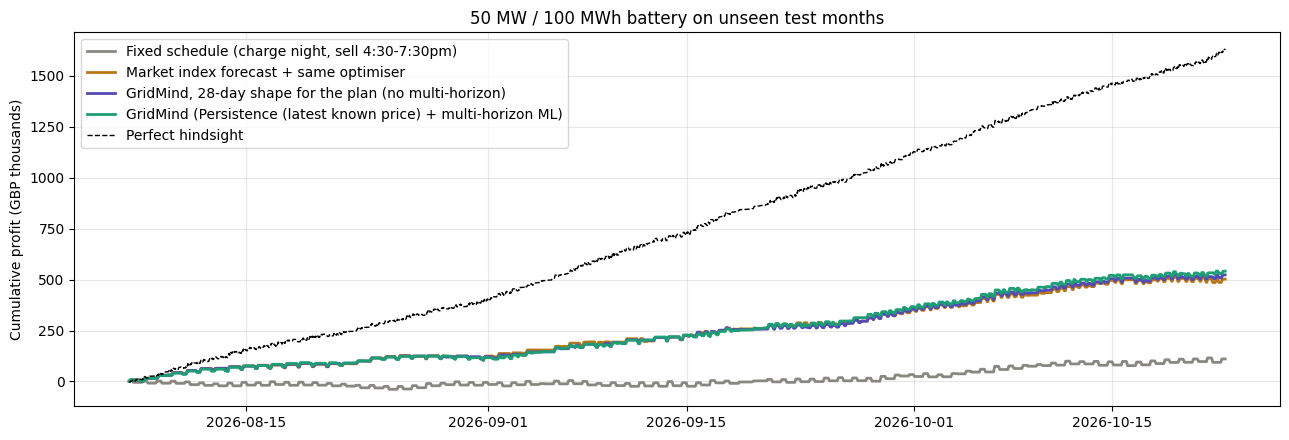

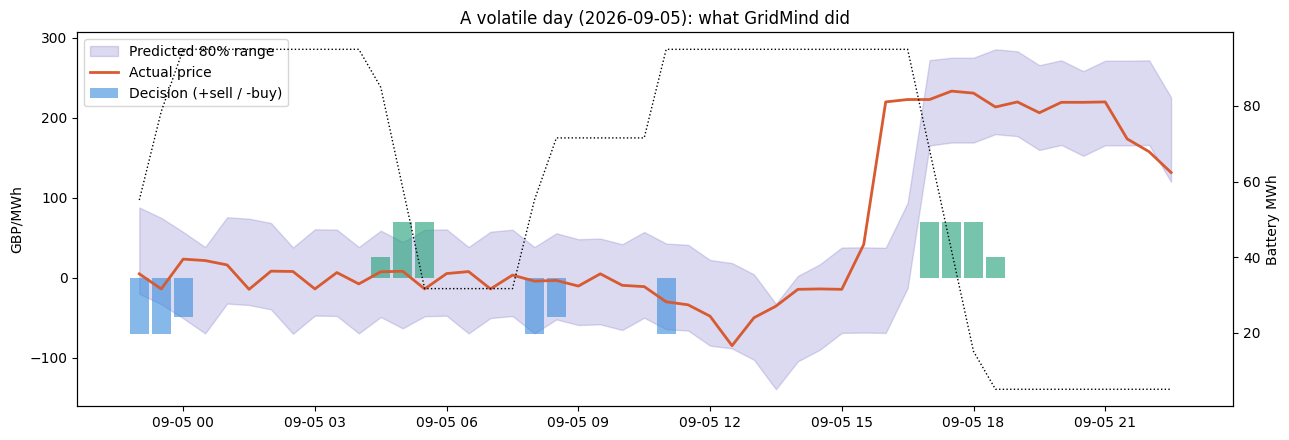

In [17]:
# ===== 15. Charts for the pitch =====
fig, ax = plt.subplots(figsize=(13, 4.5))
for (name, log), c in zip(runs.items(), ["#888780", "#BA7517", "#534AB7", "#1D9E75"]):
    ax.plot(log.startTime, log.pnl.cumsum() / 1000, label=name, color=c, lw=2)
ax.plot(ph_log.startTime, ph_log.pnl.cumsum() / 1000, label="Perfect hindsight", color="black", lw=1, ls="--")
ax.set_ylabel("Cumulative profit (GBP thousands)"); ax.set_title("50 MW / 100 MWh battery on unseen test months")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

gm = runs[GM].copy()
gm["price"] = test.price.values
for q in ("q10", "q50", "q90"): gm[q] = pred_test[q].values
gm["day"] = gm.startTime.dt.tz_convert("Europe/London").dt.date
day = gm.groupby("day")["price"].std().idxmax(); d = gm[gm.day == day]
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.fill_between(d.startTime, d.q10, d.q90, alpha=0.2, color="#534AB7", label="Predicted 80% range")
ax1.plot(d.startTime, d.price, color="#D85A30", lw=2, label="Actual price")
ax1.bar(d.startTime, d.action * d.price.abs().max() * 0.3, width=0.018,
        color=np.where(d.action > 0, "#1D9E75", "#378ADD"), alpha=0.6, label="Decision (+sell / -buy)")
ax1.set_ylabel("GBP/MWh"); ax1.legend(loc="upper left")
ax2 = ax1.twinx(); ax2.plot(d.startTime, d.soc, color="black", lw=1, ls=":"); ax2.set_ylabel("Battery MWh")
ax1.set_title(f"A volatile day ({day}): what GridMind did"); plt.tight_layout(); plt.show()

if BEST_KIND.startswith("lgb"):
    m = fit_cand(BEST_KIND, data.iloc[:i_test - GAP])
    imp = pd.Series(m.booster_.feature_importance("gain"), index=FEATURES).sort_values().tail(12)
    (imp / imp.sum()).plot.barh(figsize=(8, 4.5), color="#1D9E75", title="What the chosen model relies on")
    plt.tight_layout(); plt.show()

> **Tell the judges (method):** every model is retrained on a rolling basis as it would be live; all choices
> (model, hyperparameters, trading settings) use validation months only; the test months are touched once.

## Explainability: why does GridMind predict and decide what it does?

LightGBM can split every single forecast exactly into contributions from each input (TreeSHAP values,
built into LightGBM). We translate inputs into plain English and show: what matters on average, *how* each driver
pushes the price, and one real decision explained step by step.

**What this does:** LightGBM can split each prediction exactly into contributions from each input (TreeSHAP). These helpers translate input names into plain English and pick the top drivers of any single forecast.

In [18]:
# ===== 15b. Explainability helpers (plain-English drivers) =====
NICE = {
    "price_lag2": "Latest published imbalance price", "price_lag3": "Imbalance price 1.5h ago",
    "price_lag4": "Imbalance price 2h ago", "price_lag6": "Imbalance price 3h ago",
    "price_lag48": "Price same time yesterday", "price_lag336": "Price same time last week",
    "price_mean_6": "Average price, last 3 hours", "price_std_6": "Price volatility, last 3 hours",
    "price_max_48": "Highest price, last 24 hours", "ref_price": "Typical price this week",
    "tod_profile": "Typical price at this time of day", "profile28": "Typical price at this time of day",
    "price_vs_ref": "Latest price vs typical", "niv_lag2": "Grid short/long (imbalance volume)",
    "niv_lag3": "Grid short/long 1.5h ago", "mkt_lag1": "Latest market index price",
    "mkt_lag2": "Market index price 1h ago", "mkt_minus_ref": "Market price vs typical",
    "wind_act_lag1": "Wind output now", "wind_fc": "Wind forecast", "wind_err_lag1": "Wind surprise (actual - forecast)",
    "wind_ramp_fc": "Expected change in wind", "demand_fc": "Demand forecast",
    "residual_fc": "Demand left after wind (forecast)", "gas_lag1": "Gas generation now",
    "gas_share_lag1": "Gas share of generation", "nuclear_lag1": "Nuclear output",
    "imports_lag1": "Imports via interconnectors", "gas_ramp_lag1": "Change in gas output (last hour)",
    "hour": "Time of day", "hour_sin": "Time of day", "hour_cos": "Time of day", "weekday": "Day of week",
    "weekend": "Weekend", "month": "Month", "is_peak": "Evening peak", "wind_fc_da": "Day-ahead wind forecast",
    "demand_fc_da": "Day-ahead demand forecast", "resid_da": "Day-ahead demand left after wind",
    "k": "Hours ahead", "dev_now": "Today's price vs typical", "wind_da_change": "Forecast wind change vs now",
}

def nice(c):
    if c.startswith("now_"): return NICE.get(c[4:], c[4:])
    if c.startswith("at_"):  return NICE.get(c[3:], c[3:])
    return NICE.get(c, c)

def contrib_table(model, X):
    # exact split of each prediction into per-input contributions (+ the model's average value)
    c = model.predict(X, pred_contrib=True)
    return pd.DataFrame(c[:, :-1], columns=list(X.columns), index=X.index), c[:, -1]

def grouped(con):
    # add up inputs that mean the same thing in plain English (e.g. the three time-of-day encodings)
    return con.T.groupby([nice(c) for c in con.columns], sort=False).sum().T

def top_drivers(model, X, n=3, scale=1.0):
    con, _ = contrib_table(model, X)
    g = grouped(con.iloc[[0]] * scale).iloc[0]
    return [(name, float(g[name])) for name in g.abs().sort_values(ascending=False).index[:n]]

EXPLAINABLE = ("lgb_price", "lgb_change")
def explain_next(kind, obj, X, explain_kind=None, explain_obj=None):
    k, m = (kind, obj) if kind in EXPLAINABLE else (explain_kind, explain_obj)
    if m is None: return [], ""
    note = "" if k == kind else " (read from the LightGBM model)"
    return top_drivers(m, X[FEATURES]), note

def drivers_text(drivers):
    return [f"{name}: {'+' if v >= 0 else '-'}GBP{abs(v):,.0f}/MWh" for name, v in drivers]

**What this does:** Average impact of each input on the forecasts, plus charts showing **how** the top drivers push the price up or down.

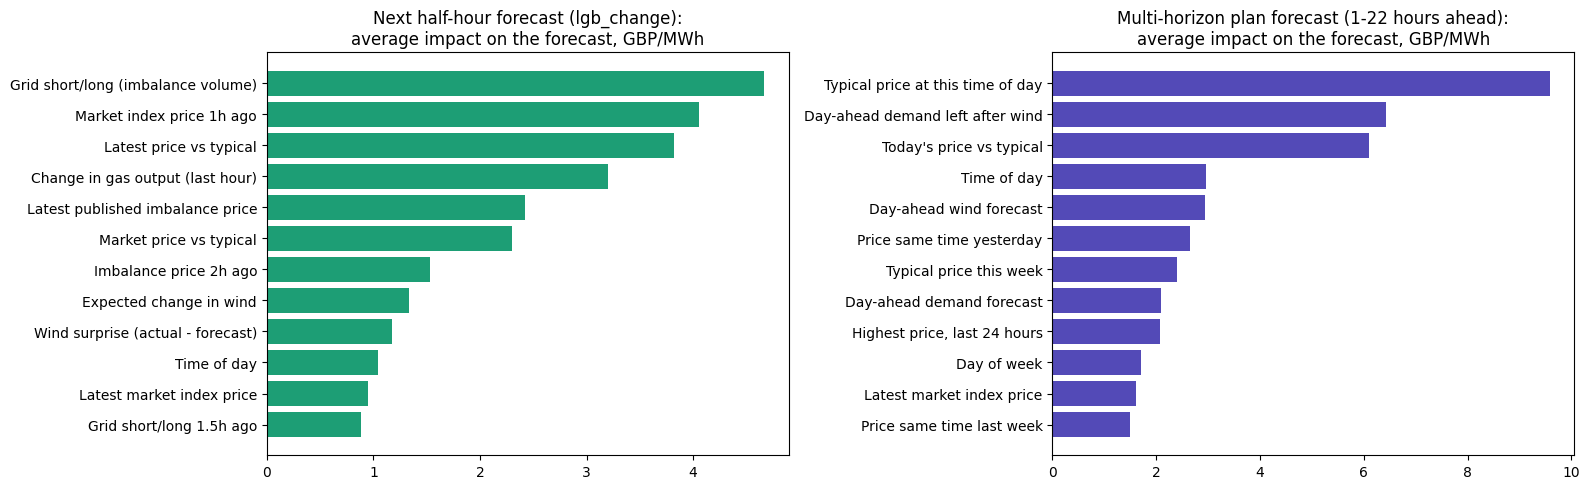

FINDINGS (how each top driver moves the forecast)
- Grid short/long (imbalance volume): higher values push the forecast UP (average impact GBP4.7/MWh, consistency 0.98)
- Market index price 1h ago: higher values push the forecast DOWN (average impact GBP4.1/MWh, consistency 0.86)
- Latest price vs typical: higher values push the forecast UP (average impact GBP3.8/MWh, consistency 0.98)
- Change in gas output (last hour): higher values push the forecast UP (average impact GBP3.2/MWh, consistency 0.93)


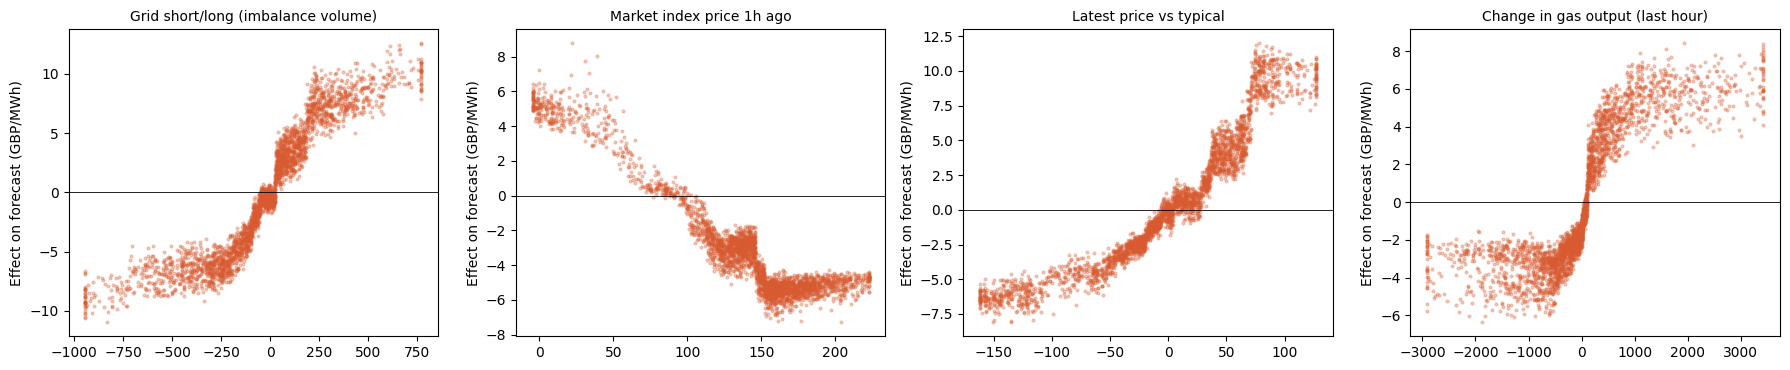

- Top drivers of the 22-hour plan: Typical price at this time of day, Day-ahead demand left after wind, Today's price vs typical


In [19]:
# ===== 15c. What drives the forecasts? (global explanation) =====
EXPLAIN_KIND = BEST_KIND if BEST_KIND in EXPLAINABLE else "lgb_change"
exp_model = fit_cand(EXPLAIN_KIND, data.iloc[:i_test - GAP])          # trained only on data before the test months
con_t, _ = contrib_table(exp_model, test[FEATURES])
IMPORTANCE = grouped(con_t).abs().mean().sort_values().tail(12)

mh_exp = fit_mh(FA_ALL, POS[:i_test:2], POS[i_test])
Xm, _, _, _ = mh_frame(FA_ALL, POS[i_test::6], np.array([1, 4, 12, 24, 43]))
con_m, _ = contrib_table(mh_exp, Xm)
IMPORTANCE_MH = grouped(con_m).abs().mean().sort_values().tail(12)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].barh(IMPORTANCE.index, IMPORTANCE.values, color="#1D9E75")
ax[0].set_title(f"Next half-hour forecast ({EXPLAIN_KIND}):\naverage impact on the forecast, GBP/MWh")
ax[1].barh(IMPORTANCE_MH.index, IMPORTANCE_MH.values, color="#534AB7")
ax[1].set_title("Multi-horizon plan forecast (1-22 hours ahead):\naverage impact on the forecast, GBP/MWh")
plt.tight_layout(); plt.show()

# How do the top drivers push the price? (dependence plots: input value vs its contribution)
raw_imp = con_t.abs().mean().sort_values(ascending=False)
top_raw = [c for c in raw_imp.index if c not in ("hour_sin", "hour_cos")][:4]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
samp = np.random.default_rng(0).choice(len(test), size=min(3000, len(test)), replace=False)
print("FINDINGS (how each top driver moves the forecast)")
for a_, c in zip(ax, top_raw):
    xv, cv = test[c].values[samp], con_t[c].values[samp]
    ok = np.isfinite(xv) & np.isfinite(cv)
    lo, hi = np.nanpercentile(xv[ok], [1, 99])
    a_.scatter(np.clip(xv[ok], lo, hi), cv[ok], s=4, alpha=0.3, color="#D85A30")
    a_.axhline(0, color="black", lw=0.6); a_.set_title(nice(c), fontsize=10); a_.set_ylabel("Effect on forecast (GBP/MWh)")
    r = pd.Series(xv[ok]).corr(pd.Series(cv[ok]), method="spearman")
    print(f"- {nice(c)}: higher values push the forecast {'UP' if r > 0 else 'DOWN'} "
          f"(average impact GBP{raw_imp[c]:.1f}/MWh, consistency {abs(r):.2f})")
plt.tight_layout(); plt.show()
print(f"- Top drivers of the 22-hour plan: {', '.join(IMPORTANCE_MH.sort_values(ascending=False).index[:3])}")

**What this does:** GridMind's most valuable sale in the test months, explained: how the forecast was built from its drivers, and the 22-hour plan the optimiser made at that moment.

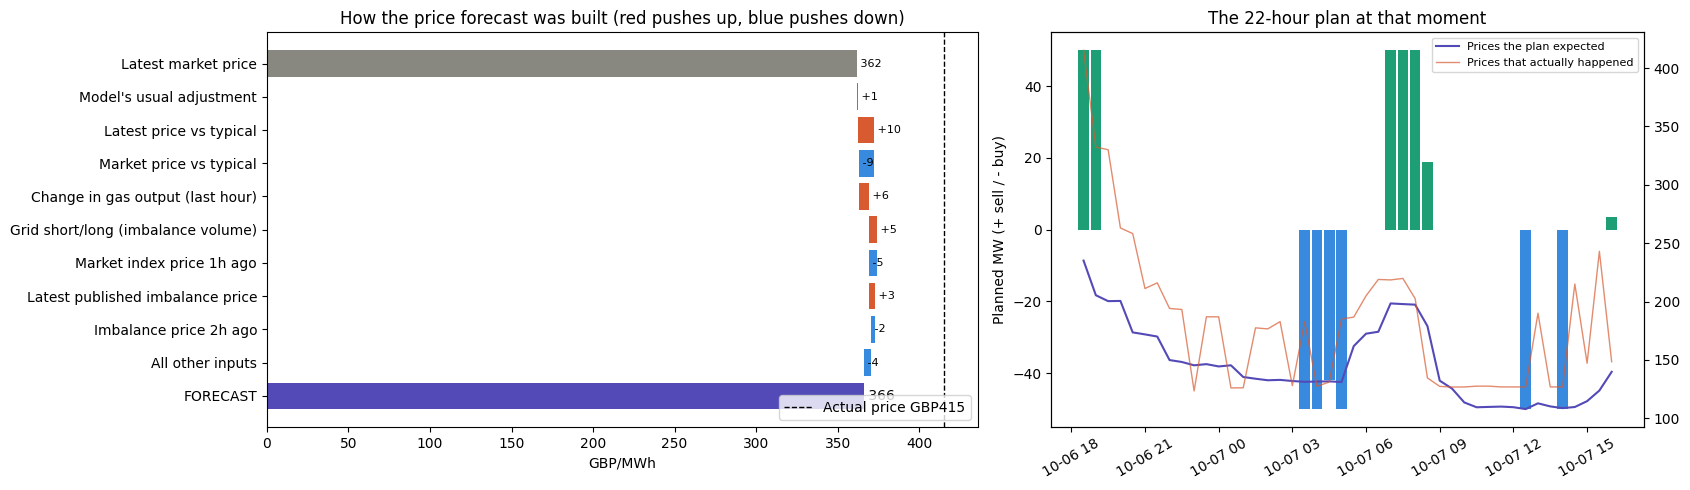

STORY FOR THE JUDGES: at Tue 06 Oct 18:30, with the battery at 58 MWh, GridMind sold at 50 MW.
- It forecast GBP366/MWh (actual: GBP415). Biggest reasons: Latest price vs typical: +GBP10/MWh; Market price vs typical: -GBP9/MWh; Change in gas output (last hour): +GBP6/MWh.
- The plan expected to recharge later at about GBP124/MWh, so selling now was worth about GBP95/MWh after efficiency losses.


In [20]:
# ===== 15d. One real decision, explained step by step =====
gm_log = runs[GM].reset_index(drop=True)
i0 = int(np.nanargmax(gm_log.action.values * test.price.values))      # GridMind's most valuable sale on test
row = test.iloc[[i0]]
con_r, ev_r = contrib_table(exp_model, row[FEATURES])
g_r = grouped(con_r).iloc[0]
top = g_r.abs().sort_values(ascending=False).index[:7]
start_lbl, start = (("Latest market price", float(row.base.iloc[0])) if EXPLAIN_KIND != "lgb_price"
                    else ("Average price (model baseline)", 0.0))
steps = [(start_lbl, start)]
if EXPLAIN_KIND != "lgb_price": steps.append(("Model's usual adjustment", float(ev_r[0])))
else: steps[0] = (start_lbl, float(ev_r[0]))
steps += [(n_, float(g_r[n_])) for n_ in top] + [("All other inputs", float(g_r.drop(top).sum()))]
forecast = sum(v for _, v in steps)

fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 1]})
cum = 0.0
for k_, (lbl, v) in enumerate(steps):
    base_ = 0 if k_ == 0 else cum
    ax[0].barh(k_, v, left=base_, color="#888780" if k_ == 0 else ("#D85A30" if v >= 0 else "#378ADD"))
    ax[0].text(base_ + v, k_, f" {v:+,.0f}" if k_ else f" {v:,.0f}", va="center", fontsize=8)
    cum += v
ax[0].barh(len(steps), forecast, color="#534AB7"); ax[0].text(forecast, len(steps), f" {forecast:,.0f}", va="center")
ax[0].set_yticks(range(len(steps) + 1)); ax[0].set_yticklabels([l for l, _ in steps] + ["FORECAST"])
ax[0].axvline(row.price.iloc[0], color="black", ls="--", lw=1, label=f"Actual price GBP{row.price.iloc[0]:,.0f}")
ax[0].invert_yaxis(); ax[0].legend(loc="lower right"); ax[0].set_xlabel("GBP/MWh")
ax[0].set_title("How the price forecast was built (red pushes up, blue pushes down)")

# the plan the optimiser made at that moment
soc0 = SOC_START if i0 == 0 else float(gm_log.soc.iloc[i0 - 1])
prof = test.profile28.values
fut = prof[i0 + 1:i0 + HORIZON]
fut = np.concatenate([fut, np.full(HZ - len(fut), prof[i0])]) if len(fut) < HZ else fut
fut = np.where(np.isfinite(FUT_TEST[i0]), FUT_TEST[i0], fut)
path = np.concatenate([[p1_test[i0]], fut])
ch_, dis_ = lp_schedule(soc0, path + KAPPA, path - KAPPA)
tt = test.startTime.iloc[i0:i0 + HORIZON].dt.tz_convert("Europe/London")
m_ = len(tt)
ax[1].bar(tt, ((dis_ - ch_) / DT)[:m_], width=0.018, color=np.where((dis_ - ch_)[:m_] > 0, "#1D9E75", "#378ADD"))
ax[1].set_ylabel("Planned MW (+ sell / - buy)")
tw = ax[1].twinx(); tw.plot(tt, path[:m_], color="#534AB7", lw=1.5, label="Prices the plan expected")
tw.plot(tt, test.price.values[i0:i0 + m_], color="#D85A30", lw=1, alpha=0.7, label="Prices that actually happened")
tw.legend(fontsize=8, loc="upper right"); ax[1].tick_params(axis="x", rotation=30)
ax[1].set_title("The 22-hour plan at that moment"); plt.tight_layout(); plt.show()

t_ = row.startTime.iloc[0].tz_convert("Europe/London")
print(f"STORY FOR THE JUDGES: at {t_:%a %d %b %H:%M}, with the battery at {soc0:.0f} MWh, GridMind sold at "
      f"{gm_log.action.iloc[i0] * P_MAX_MW:.0f} MW.")
print(f"- It forecast GBP{forecast:,.0f}/MWh (actual: GBP{row.price.iloc[0]:,.0f}). Biggest reasons: "
      + "; ".join(drivers_text([(n_, float(g_r[n_])) for n_ in top[:3]])) + ".")
sell_later = path[1:][(dis_ - ch_)[1:] > 0.5]; buy_later = path[1:][(dis_ - ch_)[1:] < -0.5]
if len(buy_later):
    print(f"- The plan expected to recharge later at about GBP{buy_later.mean():,.0f}/MWh, so selling now was worth "
          f"about GBP{path[0] - buy_later.mean() / RTE:,.0f}/MWh after efficiency losses.")

## Proof: where the value comes from, whether it is real, and whether it is robust

**What this does:** Ablation: adds one component at a time (optimiser, next-half-hour forecast, multi-horizon plan) to show how much profit each adds.

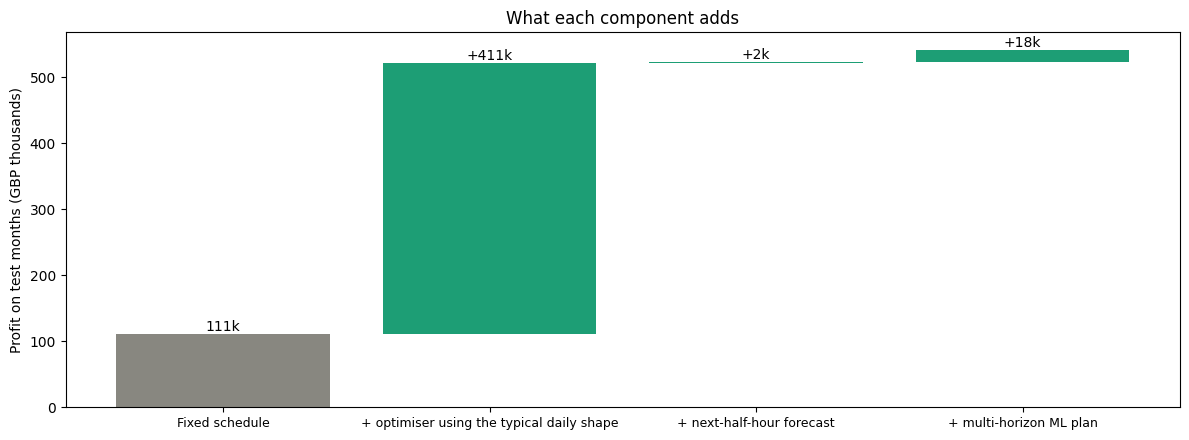

+ optimiser using the typical daily shape         +410,681 GBP
+ next-half-hour forecast                           +1,714 GBP
+ multi-horizon ML plan                            +18,198 GBP


In [21]:
# ===== 15e. Where does the value come from? (ablation) =====
abl_prof = run_mpc(test, test.profile28.values, KAPPA0)               # optimiser with NO forecasts at all
FIXED = list(runs)[0]
ABLATION = [("Fixed schedule", runs[FIXED].pnl.sum()),
            ("+ optimiser using the typical daily shape", abl_prof.pnl.sum()),
            ("+ next-half-hour forecast", runs[NOMH].pnl.sum()),
            ("+ multi-horizon ML plan" + ("" if BETA > 0 else " (not selected)"), runs[GM].pnl.sum())]
fig, ax = plt.subplots(figsize=(12, 4.5))
prev = 0.0
for k_, (lbl, tot) in enumerate(ABLATION):
    inc = tot if k_ == 0 else tot - prev
    ax.bar(k_, inc / 1000, bottom=0 if k_ == 0 else prev / 1000,
           color="#888780" if k_ == 0 else ("#1D9E75" if inc >= 0 else "#D85A30"))
    ax.text(k_, max(tot, prev) / 1000, f"{'' if k_ == 0 else ('+' if inc >= 0 else '')}{inc / 1000:,.0f}k",
            ha="center", va="bottom")
    prev = tot
ax.set_xticks(range(len(ABLATION))); ax.set_xticklabels([l for l, _ in ABLATION], fontsize=9)
ax.set_ylabel("Profit on test months (GBP thousands)"); ax.set_title("What each component adds")
plt.tight_layout(); plt.show()
for (l0, a0), (l1, a1) in zip(ABLATION, ABLATION[1:]):
    print(f"{l1:45s} {a1 - a0:+12,.0f} GBP")

**What this does:** Block bootstrap: resamples whole weeks of daily profit differences 5,000 times to see whether GridMind's edge could be luck. If the 95% interval is above zero, it is very unlikely to be.

In [22]:
# ===== 15f. Is the advantage real or luck? (block bootstrap over days) =====
def daily_pnl(log):
    return log.groupby(log.startTime.dt.tz_convert("Europe/London").dt.date)["pnl"].sum()

def block_bootstrap(diff, n_boot=5000, block=7, seed=0):
    # resample whole weeks, keeping day-to-day dependence, to get the uncertainty of the average daily difference
    rng = np.random.default_rng(seed); n_ = len(diff)
    starts = rng.integers(0, n_ - block + 1, size=(n_boot, int(np.ceil(n_ / block))))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n_]
    return diff[idx].mean(axis=1)

dg = daily_pnl(runs[GM])
SIGNIF = []
for name in [n_ for n_ in runs if n_ != GM and not (n_ == NOMH and BETA == 0)]:
    diff = (dg - daily_pnl(runs[name])).dropna().values
    boots = block_bootstrap(diff)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    SIGNIF.append({"GridMind vs": name, "Extra GBP per day": diff.mean(), "95% interval": f"{lo:,.0f} to {hi:,.0f}",
                   "Chance the edge is real": f"{(boots > 0).mean():.0%}", "Days GridMind was ahead": f"{(diff > 0).mean():.0%}"})
SIGNIF = pd.DataFrame(SIGNIF)
print(SIGNIF.to_string(index=False, formatters={"Extra GBP per day": "{:+,.0f}".format}))
print("\nRead it as: if the 95% interval is entirely above 0, the advantage is very unlikely to be luck.")

                                           GridMind vs Extra GBP per day   95% interval Chance the edge is real Days GridMind was ahead
       Fixed schedule (charge night, sell 4:30-7:30pm)            +5,520 3,597 to 7,169                    100%                     78%
                Market index forecast + same optimiser              +502  -278 to 1,092                     88%                     50%
GridMind, 28-day shape for the plan (no multi-horizon)              +233    -199 to 754                     85%                     54%

Read it as: if the 95% interval is entirely above 0, the advantage is very unlikely to be luck.


**What this does:** Reruns the backtest with different battery assumptions (efficiency, wear cost) to check the conclusion does not depend on one choice.

In [23]:
# ===== 15g. Robustness: do the results hold under different battery assumptions? =====
t0 = time.time()
SCENARIOS = [("Less efficient (85%)", 0.85, 5.0), ("More efficient (92%)", 0.92, 5.0),
             ("No wear cost", 0.88, 0.0), ("High wear cost (GBP10/MWh)", 0.88, 10.0)]
_saved = (RTE, ETA, DEG_COST)
rows_ = [{"Scenario": "Base case (88%, GBP5 wear)", "Fixed": runs[FIXED].pnl.sum(),
          "Market + optimiser": runs["Market index forecast + same optimiser"].pnl.sum(), "GridMind": runs[GM].pnl.sum()}]
try:
    for lbl, rte_, deg_ in SCENARIOS:
        RTE, ETA, DEG_COST = rte_, rte_ ** 0.5, deg_
        rows_.append({"Scenario": lbl, "Fixed": run_fixed(test).pnl.sum(),
                      "Market + optimiser": run_mpc(test, blend(test, WF[MKT][i_test:], ALPHA_M), KAPPA_M)["pnl"].sum(),
                      "GridMind": run_mpc(test, p1_test, KAPPA, future=FUT_TEST if BETA > 0 else None)["pnl"].sum()})
finally:
    RTE, ETA, DEG_COST = _saved
ROBUST = pd.DataFrame(rows_)
ROBUST["GridMind vs fixed"] = [f"{(g / f - 1) * 100:+.0f}%" if f > 0 else "" for g, f in zip(ROBUST.GridMind, ROBUST.Fixed)]
ROBUST["GridMind wins"] = np.where(ROBUST.GridMind > ROBUST[["Fixed", "Market + optimiser"]].max(axis=1), "yes", "no")
print(ROBUST.to_string(index=False, formatters={c: "{:,.0f}".format for c in ("Fixed", "Market + optimiser", "GridMind")}))
print(f"({time.time() - t0:.0f}s)")

                  Scenario   Fixed Market + optimiser GridMind GridMind vs fixed GridMind wins
Base case (88%, GBP5 wear) 110,594            502,070  541,188             +389%           yes
      Less efficient (85%)  74,171            435,064  499,166             +573%           yes
      More efficient (92%) 157,395            562,190  609,367             +287%           yes
              No wear cost 143,224            544,999  594,570             +315%           yes
High wear cost (GBP10/MWh)  77,965            436,101  496,204             +536%           yes
(104s)


**What this does:** Retrains the chosen models on all data for live use, and measures the forecast range from the latest real errors.

In [24]:
# ===== 16. Final model on ALL data, ready for live use =====
FINAL_OBJ = fit_cand(BEST_KIND, data)
res = (data.price.values - pred_all.q50.values)[i_test:]
res = res[~np.isnan(res)][-1440:]
RES_Q = (float(np.quantile(res, 0.10)), float(np.quantile(res, 0.90)))   # latest 30 days of real errors
FINAL_MH = fit_mh(FA_ALL, POS[::2], len(feat) + 3) if BETA > 0 else None
EXPLAIN_OBJ = FINAL_OBJ if EXPLAIN_KIND == BEST_KIND else fit_cand(EXPLAIN_KIND, data)   # for plain-English drivers
print(f"Final model: {BEST}, trained on {len(data):,} half-hours. Live 80% range = forecast "
      f"{RES_Q[0]:+.0f} / {RES_Q[1]:+.0f} GBP/MWh")
print("Multi-horizon model:", "trained on all data" if FINAL_MH is not None else "not used (did not win on validation)")

Final model: Persistence (latest known price), trained on 18,527 half-hours. Live 80% range = forecast -63 / +65 GBP/MWh
Multi-horizon model: trained on all data


**What this does:** Downloads the last month of live data and produces the decision for the next half-hour: forecast, 22-hour plan, action, the reason, and the main drivers.

In [25]:
# ===== 17. LIVE recommendation for the next half-hour =====
def live_plan(f, now, kind, obj, res_q, mh_model, alpha, beta, kappa, soc, explain_kind=None, explain_obj=None):
    # Shared by this notebook and the website: forecast -> 22-hour plan -> decision for the coming half-hour
    pos = np.flatnonzero((f["startTime"] > now).values)
    if len(pos) == 0: return None
    j = int(pos[0]); X = f.iloc[[j]]
    FA = arrays(f)
    typical = float(np.nanmedian(FA["price"][-336:]))
    idx = np.minimum(j + np.arange(HORIZON), len(f) - 1)
    prof = FA["profile28"][idx]; prof = np.where(np.isfinite(prof), prof, typical)
    q50 = float(predict_cand(kind, obj, X)[0])
    if not np.isfinite(q50): q50 = float(prof[0])           # newest inputs not published yet
    fut = prof[1:]
    if mh_model is not None and beta > 0:
        mh = predict_mh(mh_model, FA, np.array([j]))[0]
        fut = np.where(np.isfinite(mh), prof[1:] + beta * (mh - prof[1:]), prof[1:])
    path = np.concatenate([[prof[0] + alpha * (q50 - prof[0])], fut])
    ch, dis = lp_schedule(soc, path + kappa, path - kappa)
    a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP
    plan_mw = np.zeros(len(path)) if ch is None else (dis - ch) / DT
    act = "DISCHARGE (sell)" if a > 1e-6 else "CHARGE (buy)" if a < -1e-6 else "HOLD"
    sell_p = path[plan_mw > 0.5]; buy_p = path[plan_mw < -0.5]
    if a < -1e-6:
        why = (f"Expected price now (GBP{path[0]:,.0f}) is low compared with the later half-hours the plan sells in "
               f"(about GBP{sell_p.mean():,.0f})." if len(sell_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the lowest of the next 22 hours.")
    elif a > 1e-6:
        why = (f"Expected price now (GBP{path[0]:,.0f}) is high compared with the half-hours the plan recharges in "
               f"(about GBP{buy_p.mean():,.0f})." if len(buy_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the highest of the next 22 hours.")
    else:
        why = "Better opportunities are expected later, or the price gap is too small to cover losses and wear."
    try:
        drivers, dnote = explain_next(kind, obj, X, explain_kind, explain_obj)
    except Exception:
        drivers, dnote = [], ""
    return dict(drivers=drivers, drivers_note=dnote,
                time=X["startTime"].iloc[0].tz_convert("Europe/London"), q10=q50 + res_q[0], q50=q50,
                q90=q50 + res_q[1], typical=float(prof[0]), a=a, mw=abs(a) * P_MAX_MW, action=act, why=why,
                soc=soc, plan_times=pd.DatetimeIndex(f["startTime"].iloc[idx]), plan_price=path, plan_mw=plan_mw,
                recent=f.dropna(subset=["price"]).tail(96)[["startTime", "price"]])

def recommend(live_raw, now, current_soc=50.0, verbose=True):
    f = build_features(clean_data(live_raw, verbose=False))
    rec = live_plan(f, now, BEST_KIND, FINAL_OBJ, RES_Q, FINAL_MH, ALPHA, BETA, KAPPA, current_soc,
                    EXPLAIN_KIND, EXPLAIN_OBJ)
    if rec is None:
        if verbose: print("No upcoming period found")
        return None
    if verbose:
        print(f"\\nPeriod starting {rec['time']:%a %d %b %H:%M} (UK time)")
        print(f"Predicted imbalance price: GBP{rec['q50']:,.0f}/MWh  (80% range GBP{rec['q10']:,.0f} to GBP{rec['q90']:,.0f})")
        print(f"Typical price at this time of day: GBP{rec['typical']:,.0f}/MWh")
        print(f"Decision: {rec['action']} at {rec['mw']:.0f} MW   (battery at {current_soc:.0f} MWh)")
        print(f"Why: {rec['why']}")
        if rec["drivers"]:
            print(f"Main drivers of the forecast{rec['drivers_note']}: " + "; ".join(drivers_text(rec["drivers"])))
    return rec

_cache = {"t": 0.0, "raw": None}
def live_raw_data(max_age_s=900):
    if _cache["raw"] is None or time.time() - _cache["t"] > max_age_s:
        now = datetime.now(timezone.utc)
        prices, fuel, mid, windf, demf = fetch_all((now - timedelta(days=31)).date(), now.date())
        if prices.empty: raise RuntimeError("No live price data returned")
        _cache.update(t=time.time(), raw=combine(prices, fuel, mid, windf, demf, extend_periods=52))
    return _cache["raw"]

rec = recommend(live_raw_data(), datetime.now(timezone.utc), 50.0)

Fetching imbalance prices...
   prices 2026-10-24
Fetching fuel mix...
   fuel mix to 2026-10-24
Fetching market index...
Fetching wind forecasts...
   WINDFOR to 2026-10-24
Fetching demand forecasts...
   NDF to 2026-10-24
   prices    :    1,530 rows
   fuel      :    1,531 rows
   mid       :    1,530 rows
   wind fc   :   19,725 rows
   demand fc :   95,383 rows
\nPeriod starting Sat 24 Oct 22:00 (UK time)
Predicted imbalance price: GBP153/MWh  (80% range GBP91 to GBP218)
Typical price at this time of day: GBP153/MWh
Decision: DISCHARGE (sell) at 50 MW   (battery at 50 MWh)
Why: Expected price now (GBP153) is high compared with the half-hours the plan recharges in (about GBP103).
Main drivers of the forecast (read from the LightGBM model): Latest published imbalance price: -GBP4/MWh; Grid short/long 1.5h ago: -GBP2/MWh; Change in gas output (last hour): +GBP2/MWh


**What this does:** Saves the model and starts a temporary web app with a public link (a backup for the demo).

In [26]:
# ===== 18. DEPLOY: save the model and launch a live web app =====
joblib.dump({"best": BEST, "kind": BEST_KIND, "model": FINAL_OBJ, "features": FEATURES, "alpha": ALPHA,
             "kappa": KAPPA, "beta": BETA, "mh_model": FINAL_MH, "res_q": RES_Q,
             "explain_kind": EXPLAIN_KIND, "explain_model": EXPLAIN_OBJ,
             "battery": dict(P_MAX_MW=P_MAX_MW, E_MAX_MWH=E_MAX_MWH, RTE=RTE)}, "gridmind_model.joblib")
print("Saved gridmind_model.joblib")

try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"]); import gradio as gr

def rec_figure(rec):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
    r = rec["recent"]
    ax[0].plot(r.startTime, r.price, color="#D85A30", lw=1.8)
    ax[0].errorbar([rec["time"]], [rec["q50"]], yerr=[[rec["q50"] - rec["q10"]], [rec["q90"] - rec["q50"]]],
                   fmt="o", color="#534AB7", capsize=6, label="Next half-hour forecast")
    ax[0].set_title("Last 48h of real prices + our forecast"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
    pt = pd.to_datetime(rec["plan_times"]).tz_localize("UTC") if pd.to_datetime(rec["plan_times"]).tz is None \
        else pd.to_datetime(rec["plan_times"])
    ax[1].bar(pt, rec["plan_mw"], width=0.018, color=np.where(rec["plan_mw"] > 0, "#1D9E75", "#378ADD"))
    ax[1].set_ylabel("Planned MW (+sell / -buy)")
    ax1b = ax[1].twinx(); ax1b.plot(pt, rec["plan_price"], color="#888780", lw=1.2); ax1b.set_ylabel("Expected GBP/MWh")
    ax[1].set_title("Plan for the next 22 hours (re-planned every half-hour)"); ax[1].tick_params(axis="x", rotation=30)
    plt.tight_layout(); return fig

def app_fn(soc):
    rec = recommend(live_raw_data(), datetime.now(timezone.utc), float(soc), verbose=False)
    if rec is None: return "No upcoming period found.", None
    text = (f"### {rec['action']} at {rec['mw']:.0f} MW\n"
            f"**Period:** {rec['time']:%a %d %b %H:%M} UK time  \n"
            f"**Predicted imbalance price:** GBP{rec['q50']:,.0f}/MWh (80% range GBP{rec['q10']:,.0f} to GBP{rec['q90']:,.0f})  \n"
            f"**Typical price at this time:** GBP{rec['typical']:,.0f}/MWh  \n"
            f"**Why:** {rec['why']}  \n"
            + (f"**Main drivers{rec['drivers_note']}:** " + "; ".join(drivers_text(rec["drivers"])) + "  \n" if rec["drivers"] else "")
            + f"**Models:** {BEST} (next half-hour)" + (" + multi-horizon ML (22-hour plan)" if BETA > 0 else ""))
    return text, rec_figure(rec)

with gr.Blocks(title="GridMind") as demo:
    gr.Markdown("# GridMind: live decisions for a 50 MW / 100 MWh GB grid battery\n"
                "Real-time Elexon data -> price forecast with an 80% range -> 22-hour optimised plan.")
    soc_in = gr.Slider(5, 95, value=50, step=1, label="Battery charge now (MWh)")
    btn = gr.Button("Get recommendation for the next half-hour", variant="primary")
    out_md, out_plot = gr.Markdown(), gr.Plot()
    btn.click(app_fn, inputs=soc_in, outputs=[out_md, out_plot])

demo.launch(share=True, debug=False)   # prints a public https://...gradio.live link (valid ~72h) for the judges

Saved gridmind_model.joblib
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b8df61a0b26b221aa3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**What this does:** All the headline numbers as ready-to-say sentences.

In [27]:
# ===== 19. Your pitch numbers =====
g = table.set_index("Strategy")
gm_row, fx_row, mk_row = g.loc[GM], g.iloc[0], g.iloc[1]
print(f"Data: {len(clean):,} half-hours of real GB market data ({clean.startTime.min():%b %Y} - {clean.startTime.max():%b %Y}).")
print(f"Compared {len(CANDIDATES)} forecasting approaches with fortnightly retraining; chose {BEST} by validation profit.")
print(f"On {days} unseen days, GridMind earned GBP{gm_row['Profit (GBP)']:,.0f} vs GBP{fx_row['Profit (GBP)']:,.0f} "
      f"for a fixed schedule ({gm_row['vs fixed']}), capturing {gm_row['% of max']:.0f}% of the theoretical maximum "
      f"(about GBP{gm_row['GBP/MW/year']:,.0f} per MW per year).")
nm_row = g.loc[NOMH]
print(f"Multi-horizon ML (22-hour plan from day-ahead wind & demand forecasts): plan error GBP{np.nanmean(mt_ml):.1f} vs "
      f"GBP{np.nanmean(mt_prof):.1f} for the 28-day shape; profit GBP{gm_row['Profit (GBP)'] - nm_row['Profit (GBP)']:+,.0f} "
      f"vs the same system without it" + ("" if BETA > 0 else " (not selected on validation, so not used)") + ".")
diff = gm_row['Profit (GBP)'] - mk_row['Profit (GBP)']
print(f"Versus using the market index price with the same optimiser: GBP{diff:+,.0f}.")
print(f"Losing days: {gm_row['Losing days']} vs {fx_row['Losing days']} for the fixed schedule.")
sig_fx = SIGNIF.iloc[0]
print(f"Is it luck? vs the fixed schedule GridMind makes GBP{sig_fx['Extra GBP per day']:+,.0f}/day "
      f"(95% interval GBP{sig_fx['95% interval']}), chance the edge is real: {sig_fx['Chance the edge is real']}.")
print("Where the value comes from: " + "; ".join(f"{l1} {a1 - a0:+,.0f}" for (l0, a0), (l1, a1) in zip(ABLATION, ABLATION[1:])))
print(f"Robustness: GridMind beats both baselines in {int((ROBUST['GridMind wins'] == 'yes').sum())} of {len(ROBUST)} "
      "battery scenarios.")
print("Top drivers of the forecast: " + ", ".join(IMPORTANCE.sort_values(ascending=False).index[:3]) + ".")

Data: 18,576 half-hours of real GB market data (Sep 2025 - Oct 2026).
Compared 4 forecasting approaches with fortnightly retraining; chose Persistence (latest known price) by validation profit.
On 78 unseen days, GridMind earned GBP541,188 vs GBP110,594 for a fixed schedule (+389%), capturing 33% of the theoretical maximum (about GBP50,650 per MW per year).
Multi-horizon ML (22-hour plan from day-ahead wind & demand forecasts): plan error GBP41.4 vs GBP47.8 for the 28-day shape; profit GBP+18,198 vs the same system without it.
Versus using the market index price with the same optimiser: GBP+39,117.
Losing days: 15% vs 44% for the fixed schedule.
Is it luck? vs the fixed schedule GridMind makes GBP+5,520/day (95% interval GBP3,597 to 7,169), chance the edge is real: 100%.
Where the value comes from: + optimiser using the typical daily shape +410,681; + next-half-hour forecast +1,714; + multi-horizon ML plan +18,198
Robustness: GridMind beats both baselines in 5 of 5 battery scenarios.
T

**What this does:** Builds `gridmind_app.zip`: everything the Streamlit website needs (the app, the notebook's functions, the trained models, results, replay data and a live snapshot). Unzip it into a GitHub repository and deploy on Streamlit Community Cloud.

In [28]:
# ===== 20. Package the WEBSITE for GitHub + Streamlit Community Cloud (one zip) =====
import json, shutil, platform, importlib.metadata as md_
SITE = "gridmind_app"; os.makedirs(SITE, exist_ok=True)

joblib.dump({"best": BEST, "kind": BEST_KIND, "model": FINAL_OBJ, "features": FEATURES, "alpha": ALPHA,
             "kappa": KAPPA, "beta": BETA, "mh_model": FINAL_MH, "res_q": RES_Q,
             "explain_kind": EXPLAIN_KIND, "explain_model": EXPLAIN_OBJ}, f"{SITE}/gridmind_model.joblib")

def _daily_cum(log):
    s = log.set_index(pd.to_datetime(log.startTime, utc=True)).pnl.resample("D").sum().cumsum()
    return s
series = {k: _daily_cum(v) for k, v in runs.items()}
series["Perfect hindsight"] = _daily_cum(ph_log)
idx = series[GM].index
e_ = clean.dropna(subset=["price"]); loc_ = e_.startTime.dt.tz_convert("Europe/London")
shape = e_.assign(h=loc_.dt.hour + loc_.dt.minute / 60, we=loc_.dt.weekday >= 5).groupby(["we", "h"]).price.median().unstack(0)
g_ = table.set_index("Strategy"); gm_, fx_ = g_.loc[GM], g_.iloc[0]
results = {
    "meta": {"best": BEST, "n_candidates": len(CANDIDATES), "test_days": int(days), "rows": int(len(clean)),
             "start": f"{clean.startTime.min():%Y-%m-%d}", "end": f"{clean.startTime.max():%Y-%m-%d}"},
    "pitch": [f"{len(clean):,} half-hours of real GB market data ({clean.startTime.min():%b %Y} to {clean.startTime.max():%b %Y})",
              f"Chosen model: {BEST}, picked from {len(CANDIDATES)} candidates by validation profit",
              f"GridMind earned GBP{gm_['Profit (GBP)']:,.0f} vs GBP{fx_['Profit (GBP)']:,.0f} for a fixed schedule ({gm_['vs fixed']})",
              f"Captured {gm_['% of max']:.0f}% of the theoretical maximum, about GBP{gm_['GBP/MW/year']:,.0f} per MW per year",
              f"Losing days: {gm_['Losing days']} vs {fx_['Losing days']} for the fixed schedule",
              f"22-hour plan error: GBP{np.nanmean(mt_ml):.1f} with multi-horizon ML vs GBP{np.nanmean(mt_prof):.1f} with the 28-day shape"],
    "backtest": json.loads(table.round(1).fillna("").to_json(orient="records")),
    "comparison": json.loads(comp.round(3).fillna("").to_json(orient="records")),
    "cumulative": {"dates": [f"{d:%Y-%m-%d}" for d in idx],
                   "series": {k: [float(x) for x in v.reindex(idx).ffill().fillna(0)] for k, v in series.items()}},
    "importance": {"names": list(IMPORTANCE.index), "values": [float(v) for v in IMPORTANCE.values]},
    "importance_mh": {"names": list(IMPORTANCE_MH.index), "values": [float(v) for v in IMPORTANCE_MH.values]},
    "ablation": [{"step": l, "profit": float(v)} for l, v in ABLATION],
    "significance": json.loads(SIGNIF.round(0).to_json(orient="records")),
    "robustness": json.loads(ROBUST.round(0).to_json(orient="records")),
    "daily_shape": {"hour": [float(h) for h in shape.index], "weekday": [float(x) for x in shape[False]],
                    "weekend": [float(x) for x in shape[True]]},
}
json.dump(results, open(f"{SITE}/gridmind_results.json", "w"), indent=1)

# Replay data: every test half-hour, what GridMind and the fixed schedule did (lets the site replay any day offline)
pd.DataFrame({"startTime": test.startTime.dt.strftime("%Y-%m-%dT%H:%M:%SZ").values, "price": test.price.values,
              "q10": pred_test.q10.values, "q50": pred_test.q50.values, "q90": pred_test.q90.values,
              "gm_action": runs[GM].action.values, "gm_soc": runs[GM].soc.values, "gm_pnl": runs[GM].pnl.values,
              "fixed_action": runs[FIXED].action.values, "fixed_pnl": runs[FIXED].pnl.values}
             ).round(3).to_csv(f"{SITE}/gridmind_replay.csv", index=False)

# Snapshot of a live decision right now, so the website's first screen appears instantly
try:
    r_ = recommend(live_raw_data(), datetime.now(timezone.utc), 50.0, verbose=False)
except Exception as ex_:
    r_ = None; print("No live snapshot:", ex_)
if r_ is not None:
    iso_ = lambda ts: pd.Timestamp(ts).tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
    json.dump({"created": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"), "soc": 50.0,
               "time": iso_(r_["time"]), "action": r_["action"], "mw": float(r_["mw"]), "q10": float(r_["q10"]),
               "q50": float(r_["q50"]), "q90": float(r_["q90"]), "typical": float(r_["typical"]), "why": r_["why"],
               "drivers": [[n_, float(v_)] for n_, v_ in r_["drivers"]], "drivers_note": r_["drivers_note"],
               "plan_times": [iso_(t) for t in r_["plan_times"]], "plan_price": [float(x) for x in r_["plan_price"]],
               "plan_mw": [float(x) for x in r_["plan_mw"]],
               "recent_times": [iso_(t) for t in r_["recent"].startTime], "recent_price": [float(x) for x in r_["recent"].price]},
              open(f"{SITE}/gridmind_snapshot.json", "w"))
    print("Saved a live snapshot for the website's first screen")

open(f"{SITE}/gridmind_core.py", "w").write('# GridMind core functions (generated from the notebook; do not edit by hand)\n\nFEATURES = []   # set by app.py from the saved model\n\nimport sys, subprocess\n\nimport os, time, warnings\n\nfrom datetime import date, datetime, timedelta, timezone\n\nimport numpy as np\n\nimport pandas as pd\n\nimport requests\n\nimport lightgbm as lgb\n\nimport matplotlib.pyplot as plt\n\nfrom scipy.optimize import linprog\n\nimport joblib\n\nP_MAX_MW   = 50.0\n\nE_MAX_MWH  = 100.0\n\nSOC_MIN, SOC_MAX = 5.0, 95.0\n\nRTE        = 0.88\n\nETA        = RTE ** 0.5\n\nDEG_COST   = 5.0\n\nDT         = 0.5\n\nE_STEP     = P_MAX_MW * DT\n\nSOC_START  = 50.0\n\nTUNE_MODELS = True\n\nBASE = "https://data.elexon.co.uk/bmrs/api/v1"\n\nS = requests.Session()\n\ndef get(url, params=None, retries=3):\n    err = None\n    for _ in range(retries):\n        try:\n            r = S.get(url, params=params, timeout=90)\n            if r.status_code == 429:\n                time.sleep(5); continue\n            r.raise_for_status()\n            js = r.json()\n            return js["data"] if isinstance(js, dict) and "data" in js else js\n        except Exception as e:\n            err = e; time.sleep(2)\n    print(f"   ! request failed: {url} {params or \'\'} -> {err}")\n    return []\n\ndef chunks(start, end, days=7):\n    d = start\n    while d <= end:\n        e = min(d + timedelta(days=days - 1), end)\n        yield d, e\n        d = e + timedelta(days=1)\n\ndef iso(d):  # date -> ISO midnight UTC\n    return f"{d.isoformat()}T00:00:00Z"\n\ndef fetch_prices(start, end):\n    # Imbalance (system) price per half-hour -> our TARGET\n    rows = []\n    d = start\n    while d <= end:\n        rows += get(f"{BASE}/balancing/settlement/system-prices/{d.isoformat()}")\n        print(f"   prices {d}", end="\\r"); d += timedelta(days=1)\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df = df[["startTime", "systemSellPrice", "netImbalanceVolume"]].rename(\n        columns={"systemSellPrice": "price", "netImbalanceVolume": "niv"})\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    return df.drop_duplicates("startTime", keep="last")\n\ndef fetch_fuel(start, end):\n    # Generation by fuel type every 5 min -> half-hourly averages\n    rows = []\n    for a, b in chunks(start, end):\n        rows += get(f"{BASE}/datasets/FUELINST/stream",\n                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})\n        print(f"   fuel mix to {b}", end="\\r")\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True).dt.floor("30min")\n    return (df.pivot_table(index="startTime", columns="fuelType", values="generation", aggfunc="mean")\n              .add_prefix("gen_").reset_index())\n\ndef fetch_mid(start, end):\n    # Market Index Data: wholesale price per half-hour (volume-weighted across providers)\n    rows = []\n    for a, b in chunks(start, end):\n        rows += get(f"{BASE}/datasets/MID", {"from": iso(a), "to": iso(b + timedelta(days=1))})\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    df["pv"] = df["price"] * df["volume"]\n    g = df.groupby("startTime")[["pv", "volume", "price"]].agg({"pv": "sum", "volume": "sum", "price": "mean"})\n    g["market_price"] = np.where(g["volume"] > 0, g["pv"] / g["volume"].replace(0, np.nan), g["price"])\n    return g[["market_price"]].reset_index()\n\ndef fetch_forecast(dataset, start, end, value_col):\n    # Every published forecast (with publishTime) so we can use only what was known at the time\n    rows = []\n    for a, b in chunks(start - timedelta(days=2), end):\n        rows += get(f"{BASE}/datasets/{dataset}/stream",\n                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})\n        print(f"   {dataset} to {b}", end="\\r")\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty or value_col not in df.columns: return pd.DataFrame()\n    df = df[["publishTime", "startTime", value_col]].rename(columns={value_col: "value"})\n    df["publishTime"] = pd.to_datetime(df["publishTime"], utc=True)\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    return df.dropna()\n\ndef fetch_all(start, end):\n    print("Fetching imbalance prices..."); prices = fetch_prices(start, end)\n    print("Fetching fuel mix...");         fuel   = fetch_fuel(start, end)\n    print("Fetching market index...");     mid    = fetch_mid(start, end)\n    print("Fetching wind forecasts...");   windf  = fetch_forecast("WINDFOR", start, end, "generation")\n    print("Fetching demand forecasts..."); demf   = fetch_forecast("NDF", start, end, "demand")\n    for name, d in [("prices", prices), ("fuel", fuel), ("mid", mid), ("wind fc", windf), ("demand fc", demf)]:\n        print(f"   {name:10s}: {len(d):>8,} rows" + ("   <-- EMPTY (feature will be skipped)" if d.empty else ""))\n    return prices, fuel, mid, windf, demf\n\nFC_LEAD = pd.Timedelta("60min")\n\nDA_LEAD = pd.Timedelta("24h")\n\ndef asat(fc, times, lead=FC_LEAD, hourly=False):\n    # For each target time, the latest forecast for that time published at least `lead` earlier\n    if fc.empty: return pd.Series(np.nan, index=times)\n    t = pd.DataFrame({"startTime": times})\n    t["key"] = t["startTime"].dt.floor("60min") if hourly else t["startTime"]\n    t["cutoff"] = t["startTime"] - lead\n    f = fc.rename(columns={"startTime": "key"}).sort_values("publishTime")\n    out = pd.merge_asof(t.sort_values("cutoff"), f, left_on="cutoff", right_on="publishTime",\n                        by="key", direction="backward")\n    return out.set_index("startTime")["value"].reindex(times)\n\ndef combine(prices, fuel, mid, windf, demf, extend_periods=0):\n    t0 = prices["startTime"].min()\n    t1 = prices["startTime"].max() + pd.Timedelta(minutes=30) * extend_periods\n    grid = pd.DataFrame({"startTime": pd.date_range(t0, t1, freq="30min", tz="UTC")})\n    df = grid.merge(prices, on="startTime", how="left")\n    for extra in (fuel, mid):\n        if len(extra): df = df.merge(extra, on="startTime", how="left")\n    hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()\n    df["wind_fc"]   = asat(windf, df["startTime"], hourly=hourly).values\n    df["demand_fc"] = asat(demf, df["startTime"]).values\n    df["wind_fc_da"]   = asat(windf, df["startTime"], lead=DA_LEAD, hourly=hourly).values\n    df["demand_fc_da"] = asat(demf, df["startTime"], lead=DA_LEAD).values\n    return df\n\nFILL_LIMIT = 4\n\ndef clean_data(raw, verbose=True):\n    df = raw.copy()\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    n_dup = df.startTime.duplicated().sum()\n    df = df.drop_duplicates("startTime", keep="last").sort_values("startTime")\n    grid = pd.date_range(df.startTime.min(), df.startTime.max(), freq="30min", tz="UTC")\n    n_gap = len(grid) - len(df)\n    df = df.set_index("startTime").reindex(grid).rename_axis("startTime").reset_index()\n\n    # 1. drop columns with no information (e.g. coal after 2024) or mostly missing\n    num = df.select_dtypes("number").columns\n    drop = [c for c in num if c not in ("price", "niv", "market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da")\n            and (df[c].nunique(dropna=True) <= 1 or df[c].isna().mean() > 0.5)]\n    df = df.drop(columns=drop)\n\n    # 2. physically impossible values\n    gen_cols = [c for c in df.columns if c.startswith("gen_")]\n    clip_cols = [c for c in gen_cols if not c.startswith("gen_INT") and c != "gen_PS"]   # imports/pumping can be negative\n    n_clip = int(sum((df[c] < 0).sum() for c in clip_cols))\n    for c in clip_cols: df[c] = df[c].clip(lower=0)\n    n_bad_fc = 0\n    if "wind_fc" in df:   n_bad_fc += int((df.wind_fc < 0).sum());   df.loc[df.wind_fc < 0, "wind_fc"] = np.nan\n    if "wind_fc_da" in df: n_bad_fc += int((df.wind_fc_da < 0).sum()); df.loc[df.wind_fc_da < 0, "wind_fc_da"] = np.nan\n    if "demand_fc_da" in df: n_bad_fc += int((df.demand_fc_da <= 0).sum()); df.loc[df.demand_fc_da <= 0, "demand_fc_da"] = np.nan\n    if "demand_fc" in df: n_bad_fc += int((df.demand_fc <= 0).sum()); df.loc[df.demand_fc <= 0, "demand_fc"] = np.nan\n\n    # 3. fill short feature gaps from the PAST only (never the target)\n    feat_cols = gen_cols + [c for c in ("market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da") if c in df]\n    before = int(df[feat_cols].isna().sum().sum())\n    df[feat_cols] = df[feat_cols].ffill(limit=FILL_LIMIT)\n    n_fill = before - int(df[feat_cols].isna().sum().sum())\n\n    if verbose:\n        print(f"Removed {n_dup} duplicate rows; added {n_gap} empty rows for missing half-hours (kept as gaps)")\n        print(f"Dropped uninformative columns: {drop or \'none\'}")\n        print(f"Clipped {n_clip} negative generation values to 0; removed {n_bad_fc} impossible forecasts")\n        print(f"Forward-filled {n_fill:,} short feature gaps (<= {FILL_LIMIT * 30} min). Prices left untouched.")\n        print(f"Half-hours with a usable price: {df.price.notna().sum():,} of {len(df):,}")\n    return df\n\ndef col(df, name):\n    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)\n\ndef build_features(raw):\n    df = raw.sort_values("startTime").reset_index(drop=True).copy()\n    local = df["startTime"].dt.tz_convert("Europe/London")\n    gen = [c for c in df.columns if c.startswith("gen_")]\n    df["gas"]     = col(df, "gen_CCGT").fillna(0) + col(df, "gen_OCGT").fillna(0)\n    df["imports"] = df[[c for c in gen if c.startswith("gen_INT")]].sum(axis=1, min_count=1) if gen else np.nan\n    df["total_gen"] = df[gen].sum(axis=1, min_count=1) if gen else np.nan\n    df["wind_act"]  = col(df, "gen_WIND")\n\n    f = pd.DataFrame({"startTime": df["startTime"], "price": col(df, "price")})\n    p = df["price"]\n    for k in (2, 3, 4, 6, 48, 336):                      # 48 = same time yesterday, 336 = last week\n        f[f"price_lag{k}"] = p.shift(k)\n    known = p.shift(2)\n    f["price_mean_6"]  = known.rolling(6, min_periods=3).mean()\n    f["price_std_6"]   = known.rolling(6, min_periods=3).std()\n    f["price_max_48"]  = known.rolling(48, min_periods=12).max()\n    f["ref_price"]     = known.rolling(336, min_periods=48).median()   # 7-day typical price\n    # typical price at this time of day over the last 7 days (all already published)\n    f["tod_profile"]   = pd.concat([p.shift(48 * k) for k in range(1, 8)], axis=1).median(axis=1)\n    # smoother 28-day daily shape used for planning ahead (still only published prices)\n    f["profile28"] = (pd.concat([p.shift(48 * k) for k in range(1, 29)], axis=1).median(axis=1)\n                        .rolling(5, center=True, min_periods=1).median())\n    f["price_vs_ref"]  = f["price_lag2"] - f["ref_price"]\n    f["niv_lag2"]      = col(df, "niv").shift(2)\n    f["niv_lag3"]      = col(df, "niv").shift(3)\n    f["mkt_lag1"]      = col(df, "market_price").shift(1)\n    f["mkt_lag2"]      = col(df, "market_price").shift(2)\n    f["mkt_minus_ref"] = f["mkt_lag1"] - f["ref_price"]\n    f["wind_act_lag1"] = df["wind_act"].shift(1)\n    f["wind_fc"]       = col(df, "wind_fc")\n    f["wind_err_lag1"] = df["wind_act"].shift(1) - col(df, "wind_fc").shift(1)   # +: more wind than expected\n    f["wind_ramp_fc"]  = col(df, "wind_fc") - df["wind_act"].shift(1)            # expected change in wind\n    f["demand_fc"]     = col(df, "demand_fc")\n    f["residual_fc"]   = col(df, "demand_fc") - col(df, "wind_fc")                      # demand left for gas etc.\n    f["gas_lag1"]      = df["gas"].shift(1)\n    f["gas_share_lag1"] = (df["gas"] / df["total_gen"]).shift(1)\n    f["nuclear_lag1"]  = col(df, "gen_NUCLEAR").shift(1)\n    f["imports_lag1"]  = df["imports"].shift(1)\n    f["gas_ramp_lag1"] = df["gas"].shift(1) - df["gas"].shift(3)\n    hr = local.dt.hour + local.dt.minute / 60\n    f["hour"] = hr\n    f["hour_sin"], f["hour_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)\n    f["weekday"] = local.dt.weekday\n    f["weekend"] = (local.dt.weekday >= 5).astype(int)\n    f["month"]   = local.dt.month\n    f["is_peak"] = ((hr >= 16) & (hr < 19.5)).astype(int)\n    # latest market price: the anchor for change models. Live, the newest prices may not be published yet,\n    # so fall back to the most recent known value (forward-fill uses only the past)\n    f["base"] = f["mkt_lag1"].fillna(f["price_lag2"]).ffill()\n    # day-ahead forecasts (published >= 24h before each half-hour): inputs to the multi-horizon model\n    f["wind_fc_da"]   = col(df, "wind_fc_da")\n    f["demand_fc_da"] = col(df, "demand_fc_da")\n    f["resid_da"]     = f["demand_fc_da"] - f["wind_fc_da"]\n    f["local_date"] = local.dt.date\n    return f\n\ndef step(soc, action, price):\n    # action in [-1, 1]: + = discharge, - = charge (fraction of max power)\n    if action > 1e-9:\n        out = min(action * E_STEP, (soc - SOC_MIN) * ETA)\n        return soc - out / ETA, 0.0, out, out * price - DEG_COST * out\n    if action < -1e-9:\n        inn = min(-action * E_STEP, (SOC_MAX - soc) / ETA)\n        return soc + inn * ETA, inn, 0.0, -inn * price\n    return soc, 0.0, 0.0, 0.0\n\ndef lp_schedule(soc0, p_buy, p_sell, end_soc=SOC_START, end_equal=False):\n    # Best charge/discharge plan over the horizon for given buy/sell price paths (linear program)\n    n = len(p_buy)\n    c = np.concatenate([p_buy, -p_sell + DEG_COST, np.zeros(n)])\n    A = np.zeros((n, 3 * n)); b = np.zeros(n)\n    idx = np.arange(n)\n    A[idx, idx] = -ETA; A[idx, n + idx] = 1 / ETA; A[idx, 2 * n + idx] = 1\n    A[idx[1:], 2 * n + idx[1:] - 1] = -1; b[0] = soc0\n    bounds = [(0, E_STEP)] * (2 * n) + [(SOC_MIN, SOC_MAX)] * n\n    term = np.zeros((1, 3 * n)); term[0, -1] = 1\n    if end_equal:\n        res = linprog(c, A_eq=np.vstack([A, term]), b_eq=np.append(b, end_soc), bounds=bounds, method="highs")\n    else:\n        res = linprog(c, A_eq=A, b_eq=b, A_ub=-term, b_ub=[-min(end_soc, SOC_MAX)], bounds=bounds, method="highs")\n    if not res.success: return None, None\n    return res.x[:n], res.x[n:2 * n]\n\nHORIZON = 44\n\ndef run_mpc(df, p1, kappa=0.0, soc=SOC_START, future=None):\n    # Rolling optimisation: every half-hour, plan the next 22h, do only the first step, then re-plan.\n    #   step 1 price  = p1 (our forecast for the coming half-hour)\n    #   later steps   = typical price for that time of day (28-day median, already published)\n    #   kappa         = trading hurdle (GBP/MWh) so the plan ignores spreads smaller than forecast noise\n    #   future        = optional (rows x 43) forecast for steps 2..44, replacing the typical shape\n    actual, prof = df["price"].values, df["profile28"].values\n    log = []\n    for i in range(len(df)):\n        fut = prof[i + 1:i + HORIZON]\n        if len(fut) < HORIZON - 1:\n            fut = np.concatenate([fut, np.full(HORIZON - 1 - len(fut), prof[i])])\n        if future is not None:          # optional forecast for the later steps (multi-horizon model)\n            fz = future[i]\n            fut = np.where(np.isfinite(fz), fz, fut)\n        path = np.concatenate([[p1[i]], fut])\n        ch, dis = lp_schedule(soc, path + kappa, path - kappa)\n        a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP\n        soc, e_in, e_out, pnl = step(soc, a, actual[i])\n        log.append((df["startTime"].iloc[i], a, soc, e_in, e_out, pnl))\n    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])\n\ndef blend(df, forecast, alpha):\n    # Trust the forecast in proportion to its proven skill: alpha=1 uses it fully, 0 ignores it\n    prof = df["profile28"].values\n    return prof + alpha * (np.asarray(forecast) - prof)\n\ndef run_fixed(df, soc=SOC_START):\n    # What many simple sites do: charge overnight, discharge at the evening peak\n    log = []\n    for t, h, p in zip(df["startTime"], df["hour"], df["price"]):\n        a = -1.0 if 1 <= h < 4.5 else 1.0 if 16.5 <= h < 19.5 else 0.0\n        soc, e_in, e_out, pnl = step(soc, a, p)\n        log.append((t, a, soc, e_in, e_out, pnl))\n    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])\n\ndef perfect_hindsight(df, soc0=SOC_START):\n    # Upper bound: the best possible schedule for each day if every price were known in advance\n    total, out = 0.0, []\n    for _, d in df.groupby("local_date", sort=True):\n        p = d["price"].values\n        ch, dis = lp_schedule(soc0, p, p, end_soc=soc0, end_equal=True)\n        if ch is None: continue\n        pnl = p * dis - p * ch - DEG_COST * dis\n        total += pnl.sum()\n        out.append(pd.DataFrame({"startTime": d["startTime"].values, "pnl": pnl}))\n    return total, pd.concat(out) if out else pd.DataFrame(columns=["startTime", "pnl"])\n\nCHUNK, GAP = 672, 2\n\nLGB_PARAMS = dict(n_estimators=500, learning_rate=0.04, num_leaves=31, min_child_samples=50,\n                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)\n\ndef fit_cand(kind, df):\n    # the two simple baselines need no training\n    if kind in ("persist", "market"): return None\n    # LightGBM with "l1" loss = predicts the median, so rare price spikes don\'t dominate training\n    if kind == "lgb_price":                      # learns the price directly\n        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price)\n    if kind == "lgb_change":                     # learns the CHANGE from the latest market price (adapts to price level)\n        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price - df.base)\n    raise ValueError(kind)\n\ndef predict_cand(kind, obj, df):\n    if kind == "persist":    return df.price_lag2.values                     # "price stays as last published"\n    if kind == "market":     return df.base.values                           # "price = latest market price"\n    if kind == "lgb_price":  return obj.predict(df[FEATURES])\n    if kind == "lgb_change": return df.base.values + obj.predict(df[FEATURES])\n    raise ValueError(kind)\n\ndef walk_forward(kind):\n    out = np.full(n, np.nan)\n    for s in range(WF_START, n, CHUNK):\n        e_ = min(s + CHUNK, n)\n        obj = fit_cand(kind, data.iloc[:s - GAP])\n        out[s:e_] = predict_cand(kind, obj, data.iloc[s:e_])\n    return out\n\ndef band(q50, window=1440):\n    # 80% range from the last 30 days of REAL out-of-sample errors (only errors already known)\n    res = pd.Series(data.price.values - q50).shift(GAP)\n    lo = res.rolling(window, min_periods=200).quantile(0.10).values\n    hi = res.rolling(window, min_periods=200).quantile(0.90).values\n    return pd.DataFrame({"q10": q50 + lo, "q50": q50, "q90": q50 + hi}, index=data.index)\n\nHZ = HORIZON - 1\n\nNOW_COLS = ["price_lag2", "price_mean_6", "price_std_6", "price_max_48", "ref_price", "niv_lag2",\n            "wind_err_lag1", "wind_act_lag1", "gas_lag1", "mkt_lag1"]\n\nAT_COLS = ["hour", "weekday", "weekend", "month", "is_peak", "profile28", "tod_profile", "price_lag48",\n           "price_lag336", "wind_fc_da", "demand_fc_da", "resid_da"]\n\nMH_KS_TRAIN = np.array([1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 28, 32, 38, 43])\n\nMH_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=100,\n                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)\n\ndef arrays(f):\n    return {c: pd.to_numeric(f[c], errors="coerce").values.astype(float) for c in f.columns\n            if c not in ("startTime", "local_date")}\n\ndef mh_frame(FA, js, ks):\n    # one row per (decision half-hour j, steps ahead k); target = price at j+k minus its typical value\n    N = len(FA["price"])\n    J = np.repeat(np.asarray(js), len(ks)); K = np.tile(np.asarray(ks), len(js))\n    valid = (J + K) < N\n    T = np.minimum(J + K, N - 1)\n    nan = np.full(len(J), np.nan)\n    X = {f"now_{c}": FA.get(c, nan)[J] if c in FA else nan for c in NOW_COLS}\n    X.update({f"at_{c}": FA[c][T] if c in FA else nan for c in AT_COLS})\n    X["k"] = K\n    X["dev_now"] = FA["base"][J] - FA["profile28"][J]\n    X["wind_da_change"] = (FA["wind_fc_da"][T] if "wind_fc_da" in FA else nan) - FA["wind_act_lag1"][J]\n    y = FA["price"][T] - FA["profile28"][T]\n    return pd.DataFrame(X), y, T, valid\n\ndef fit_mh(FA, train_js, cutoff_pos, params=None):\n    X, y, T, valid = mh_frame(FA, train_js, MH_KS_TRAIN)\n    ok = valid & (T <= cutoff_pos - 3) & np.isfinite(y)       # only targets already published at cutoff\n    return lgb.LGBMRegressor(objective="l1", **(params or MH_PARAMS)).fit(X[ok], y[ok])\n\ndef predict_mh(model, FA, js):\n    ks = np.arange(1, HZ + 1)\n    X, _, T, valid = mh_frame(FA, js, ks)\n    p = model.predict(X) + FA["profile28"][T]\n    p[~valid] = np.nan\n    return p.reshape(len(js), HZ)\n\ndef future_path(lo, hi, beta):\n    # plan prices for steps 2..44: typical shape moved towards the ML forecast by `beta` (0 = old behaviour)\n    prof, mh = PROF_FUT[lo:hi], MH[lo:hi]\n    return np.where(np.isfinite(mh) & np.isfinite(prof), prof + beta * (mh - prof), prof)\n\ndef mae_by_k(pred, lo, hi):\n    a = ACT_FUT[lo:hi]; m = np.isfinite(a) & np.isfinite(pred[lo:hi])\n    return np.array([np.mean(np.abs(a[:, k] - pred[lo:hi, k])[m[:, k]]) for k in range(HZ)])\n\nNICE = {\n    "price_lag2": "Latest published imbalance price", "price_lag3": "Imbalance price 1.5h ago",\n    "price_lag4": "Imbalance price 2h ago", "price_lag6": "Imbalance price 3h ago",\n    "price_lag48": "Price same time yesterday", "price_lag336": "Price same time last week",\n    "price_mean_6": "Average price, last 3 hours", "price_std_6": "Price volatility, last 3 hours",\n    "price_max_48": "Highest price, last 24 hours", "ref_price": "Typical price this week",\n    "tod_profile": "Typical price at this time of day", "profile28": "Typical price at this time of day",\n    "price_vs_ref": "Latest price vs typical", "niv_lag2": "Grid short/long (imbalance volume)",\n    "niv_lag3": "Grid short/long 1.5h ago", "mkt_lag1": "Latest market index price",\n    "mkt_lag2": "Market index price 1h ago", "mkt_minus_ref": "Market price vs typical",\n    "wind_act_lag1": "Wind output now", "wind_fc": "Wind forecast", "wind_err_lag1": "Wind surprise (actual - forecast)",\n    "wind_ramp_fc": "Expected change in wind", "demand_fc": "Demand forecast",\n    "residual_fc": "Demand left after wind (forecast)", "gas_lag1": "Gas generation now",\n    "gas_share_lag1": "Gas share of generation", "nuclear_lag1": "Nuclear output",\n    "imports_lag1": "Imports via interconnectors", "gas_ramp_lag1": "Change in gas output (last hour)",\n    "hour": "Time of day", "hour_sin": "Time of day", "hour_cos": "Time of day", "weekday": "Day of week",\n    "weekend": "Weekend", "month": "Month", "is_peak": "Evening peak", "wind_fc_da": "Day-ahead wind forecast",\n    "demand_fc_da": "Day-ahead demand forecast", "resid_da": "Day-ahead demand left after wind",\n    "k": "Hours ahead", "dev_now": "Today\'s price vs typical", "wind_da_change": "Forecast wind change vs now",\n}\n\ndef nice(c):\n    if c.startswith("now_"): return NICE.get(c[4:], c[4:])\n    if c.startswith("at_"):  return NICE.get(c[3:], c[3:])\n    return NICE.get(c, c)\n\ndef contrib_table(model, X):\n    # exact split of each prediction into per-input contributions (+ the model\'s average value)\n    c = model.predict(X, pred_contrib=True)\n    return pd.DataFrame(c[:, :-1], columns=list(X.columns), index=X.index), c[:, -1]\n\ndef grouped(con):\n    # add up inputs that mean the same thing in plain English (e.g. the three time-of-day encodings)\n    return con.T.groupby([nice(c) for c in con.columns], sort=False).sum().T\n\ndef top_drivers(model, X, n=3, scale=1.0):\n    con, _ = contrib_table(model, X)\n    g = grouped(con.iloc[[0]] * scale).iloc[0]\n    return [(name, float(g[name])) for name in g.abs().sort_values(ascending=False).index[:n]]\n\nEXPLAINABLE = ("lgb_price", "lgb_change")\n\ndef explain_next(kind, obj, X, explain_kind=None, explain_obj=None):\n    k, m = (kind, obj) if kind in EXPLAINABLE else (explain_kind, explain_obj)\n    if m is None: return [], ""\n    note = "" if k == kind else " (read from the LightGBM model)"\n    return top_drivers(m, X[FEATURES]), note\n\ndef drivers_text(drivers):\n    return [f"{name}: {\'+\' if v >= 0 else \'-\'}GBP{abs(v):,.0f}/MWh" for name, v in drivers]\n\ndef live_plan(f, now, kind, obj, res_q, mh_model, alpha, beta, kappa, soc, explain_kind=None, explain_obj=None):\n    # Shared by this notebook and the website: forecast -> 22-hour plan -> decision for the coming half-hour\n    pos = np.flatnonzero((f["startTime"] > now).values)\n    if len(pos) == 0: return None\n    j = int(pos[0]); X = f.iloc[[j]]\n    FA = arrays(f)\n    typical = float(np.nanmedian(FA["price"][-336:]))\n    idx = np.minimum(j + np.arange(HORIZON), len(f) - 1)\n    prof = FA["profile28"][idx]; prof = np.where(np.isfinite(prof), prof, typical)\n    q50 = float(predict_cand(kind, obj, X)[0])\n    if not np.isfinite(q50): q50 = float(prof[0])           # newest inputs not published yet\n    fut = prof[1:]\n    if mh_model is not None and beta > 0:\n        mh = predict_mh(mh_model, FA, np.array([j]))[0]\n        fut = np.where(np.isfinite(mh), prof[1:] + beta * (mh - prof[1:]), prof[1:])\n    path = np.concatenate([[prof[0] + alpha * (q50 - prof[0])], fut])\n    ch, dis = lp_schedule(soc, path + kappa, path - kappa)\n    a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP\n    plan_mw = np.zeros(len(path)) if ch is None else (dis - ch) / DT\n    act = "DISCHARGE (sell)" if a > 1e-6 else "CHARGE (buy)" if a < -1e-6 else "HOLD"\n    sell_p = path[plan_mw > 0.5]; buy_p = path[plan_mw < -0.5]\n    if a < -1e-6:\n        why = (f"Expected price now (GBP{path[0]:,.0f}) is low compared with the later half-hours the plan sells in "\n               f"(about GBP{sell_p.mean():,.0f})." if len(sell_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the lowest of the next 22 hours.")\n    elif a > 1e-6:\n        why = (f"Expected price now (GBP{path[0]:,.0f}) is high compared with the half-hours the plan recharges in "\n               f"(about GBP{buy_p.mean():,.0f})." if len(buy_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the highest of the next 22 hours.")\n    else:\n        why = "Better opportunities are expected later, or the price gap is too small to cover losses and wear."\n    try:\n        drivers, dnote = explain_next(kind, obj, X, explain_kind, explain_obj)\n    except Exception:\n        drivers, dnote = [], ""\n    return dict(drivers=drivers, drivers_note=dnote,\n                time=X["startTime"].iloc[0].tz_convert("Europe/London"), q10=q50 + res_q[0], q50=q50,\n                q90=q50 + res_q[1], typical=float(prof[0]), a=a, mw=abs(a) * P_MAX_MW, action=act, why=why,\n                soc=soc, plan_times=pd.DatetimeIndex(f["startTime"].iloc[idx]), plan_price=path, plan_mw=plan_mw,\n                recent=f.dropna(subset=["price"]).tail(96)[["startTime", "price"]])\n\ndef recommend(live_raw, now, current_soc=50.0, verbose=True):\n    f = build_features(clean_data(live_raw, verbose=False))\n    rec = live_plan(f, now, BEST_KIND, FINAL_OBJ, RES_Q, FINAL_MH, ALPHA, BETA, KAPPA, current_soc,\n                    EXPLAIN_KIND, EXPLAIN_OBJ)\n    if rec is None:\n        if verbose: print("No upcoming period found")\n        return None\n    if verbose:\n        print(f"\\\\nPeriod starting {rec[\'time\']:%a %d %b %H:%M} (UK time)")\n        print(f"Predicted imbalance price: GBP{rec[\'q50\']:,.0f}/MWh  (80% range GBP{rec[\'q10\']:,.0f} to GBP{rec[\'q90\']:,.0f})")\n        print(f"Typical price at this time of day: GBP{rec[\'typical\']:,.0f}/MWh")\n        print(f"Decision: {rec[\'action\']} at {rec[\'mw\']:.0f} MW   (battery at {current_soc:.0f} MWh)")\n        print(f"Why: {rec[\'why\']}")\n        if rec["drivers"]:\n            print(f"Main drivers of the forecast{rec[\'drivers_note\']}: " + "; ".join(drivers_text(rec["drivers"])))\n    return rec\n\ndef live_raw_data(max_age_s=900):\n    if _cache["raw"] is None or time.time() - _cache["t"] > max_age_s:\n        now = datetime.now(timezone.utc)\n        prices, fuel, mid, windf, demf = fetch_all((now - timedelta(days=31)).date(), now.date())\n        if prices.empty: raise RuntimeError("No live price data returned")\n        _cache.update(t=time.time(), raw=combine(prices, fuel, mid, windf, demf, extend_periods=52))\n    return _cache["raw"]\n')
open(f"{SITE}/streamlit_app.py", "w").write('# GridMind: decides every 30 minutes when a grid battery should charge or discharge,\n# using real GB electricity market data from Elexon.  Run locally with:  streamlit run streamlit_app.py\n#\n# Tabs:   Live decision  -> what the battery should do in the next half-hour, and why\n#         Replay a day   -> what GridMind did on any past test day (works offline)\n#         Results        -> backtest, where the value comes from, is it luck, robustness\n#         Explainability -> what drives the forecasts\n#         How it works   -> the method in plain English\nimport json\nimport os\nfrom datetime import datetime, timedelta, timezone\n\nimport joblib\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport streamlit as st\n\nimport gridmind_core as core   # the notebook\'s own functions: data download, cleaning, features, models, optimiser\n\nst.set_page_config(page_title="GridMind", page_icon="⚡", layout="wide")\nHERE = os.path.dirname(os.path.abspath(__file__))\nGREEN, BLUE, CORAL, PURPLE, GRAY, AMBER = "#1D9E75", "#378ADD", "#D85A30", "#534AB7", "#888780", "#BA7517"\nplt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})\nUK = "Europe/London"\n\n\n# ------------------------------------------------------------------ load saved files once (cached across visitors)\n@st.cache_resource\ndef load_all():\n    def js(name):\n        p = os.path.join(HERE, name)\n        return json.load(open(p)) if os.path.exists(p) else {}\n    bundle = joblib.load(os.path.join(HERE, "gridmind_model.joblib"))   # trained models + settings chosen on validation\n    rp_path = os.path.join(HERE, "gridmind_replay.csv")\n    rp = pd.read_csv(rp_path, parse_dates=["startTime"]) if os.path.exists(rp_path) else pd.DataFrame()\n    if not rp.empty:\n        rp["day"] = rp.startTime.dt.tz_convert(UK).dt.date\n    return bundle, js("gridmind_results.json"), js("gridmind_snapshot.json"), rp\n\nB, R, SNAP, RP = load_all()\ncore.FEATURES = B["features"]\n\n\n# ------------------------------------------------------------------ live decision\n@st.cache_data(ttl=900, show_spinner=False)     # download at most every 15 minutes, shared by all visitors\ndef live_raw():\n    now = datetime.now(timezone.utc)\n    prices, fuel, mid, windf, demf = core.fetch_all((now - timedelta(days=31)).date(), now.date())\n    if prices.empty:\n        raise RuntimeError("Elexon returned no price data. Please try again in a minute.")\n    return core.combine(prices, fuel, mid, windf, demf, extend_periods=52)\n\ndef recommend(raw, now, soc):\n    f = core.build_features(core.clean_data(raw, verbose=False))\n    return core.live_plan(f, now, B["kind"], B["model"], B["res_q"], B.get("mh_model"), B["alpha"],\n                          B.get("beta", 0.0), B["kappa"], soc, B.get("explain_kind"), B.get("explain_model"))\n\ndef show_decision(rec, soc, note):\n    icon = {"DISCHARGE (sell)": "🟢", "CHARGE (buy)": "🔵", "HOLD": "⚪"}[rec["action"]]\n    st.subheader(f"{icon} {rec[\'action\']} at {rec[\'mw\']:.0f} MW")\n    st.caption(f"Half-hour starting {rec[\'time\'].tz_convert(UK):%a %d %b, %H:%M} (UK time) · battery at {soc:.0f} of 100 MWh")\n    c1, c2, c3 = st.columns(3)\n    c1.metric("Predicted imbalance price", f"£{rec[\'q50\']:,.0f}/MWh")\n    c2.metric("80% range", f"£{rec[\'q10\']:,.0f} – £{rec[\'q90\']:,.0f}")\n    c3.metric("Typical at this time of day", f"£{rec[\'typical\']:,.0f}/MWh")\n    st.markdown(f"**Why:** {rec[\'why\']}")\n    if rec.get("drivers"):\n        st.markdown(f"**Main drivers of the forecast{rec.get(\'drivers_note\', \'\')}:**\\n" + "\\n".join(\n            f"- {\'🔺\' if v >= 0 else \'🔻\'} {n}: {\'+\' if v >= 0 else \'−\'}£{abs(v):,.0f}/MWh" for n, v in rec["drivers"]))\n    st.pyplot(live_figure(rec))\n    st.caption(note)\n\ndef live_figure(rec):\n    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})\n    r = rec["recent"]\n    ax[0].plot(r.startTime.dt.tz_convert(UK), r.price, color=CORAL, lw=1.8, label="Real imbalance price")\n    ax[0].errorbar([rec["time"].tz_convert(UK)], [rec["q50"]], yerr=[[rec["q50"] - rec["q10"]], [rec["q90"] - rec["q50"]]],\n                   fmt="o", color=PURPLE, capsize=6, label="Our forecast (80% range)")\n    ax[0].set_title("Last 48 hours + next half-hour"); ax[0].set_ylabel("£/MWh")\n    ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", rotation=30)\n    pt = rec["plan_times"].tz_convert(UK)\n    ax[1].bar(pt, rec["plan_mw"], width=0.018, color=np.where(rec["plan_mw"] > 0, GREEN, BLUE))\n    ax[1].axhline(0, color="black", lw=0.6); ax[1].set_ylabel("Planned MW (+ sell, − buy)")\n    tw = ax[1].twinx(); tw.plot(pt, rec["plan_price"], color=GRAY, lw=1.2); tw.set_ylabel("Expected £/MWh")\n    tw.spines["right"].set_visible(True)\n    ax[1].set_title("22-hour plan (re-planned every half-hour)"); ax[1].tick_params(axis="x", rotation=30)\n    fig.tight_layout()\n    return fig\n\ndef snapshot_rec():\n    rec = dict(SNAP)\n    rec["time"] = pd.Timestamp(SNAP["time"])\n    rec["plan_times"] = pd.DatetimeIndex(pd.to_datetime(SNAP["plan_times"], utc=True))\n    rec["plan_mw"], rec["plan_price"] = np.array(SNAP["plan_mw"]), np.array(SNAP["plan_price"])\n    rec["recent"] = pd.DataFrame({"startTime": pd.to_datetime(SNAP["recent_times"], utc=True), "price": SNAP["recent_price"]})\n    return rec\n\n\n# ------------------------------------------------------------------ replay a past day (no internet needed)\ndef replay_figure(d):\n    t = d.startTime.dt.tz_convert(UK)\n    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})\n    ax[0].fill_between(t, d.q10, d.q90, color=PURPLE, alpha=0.15, label="Forecast 80% range")\n    ax[0].plot(t, d.q50, color=PURPLE, lw=1.2, label="Forecast")\n    ax[0].plot(t, d.price, color=CORAL, lw=2, label="Actual price")\n    ax[0].set_ylabel("£/MWh"); ax[0].legend(fontsize=8, loc="upper left")\n    mw = d.gm_action * core.P_MAX_MW\n    ax[1].bar(t, mw, width=0.018, color=np.where(mw > 0, GREEN, BLUE), label="GridMind (+ sell, − buy)")\n    ax[1].step(t, d.fixed_action * core.P_MAX_MW, where="mid", color=GRAY, lw=1, label="Fixed schedule")\n    ax[1].set_ylabel("MW"); ax[1].legend(fontsize=8, loc="upper left")\n    tw = ax[1].twinx(); tw.plot(t, d.gm_soc, color="black", lw=1, ls=":"); tw.set_ylabel("Battery MWh")\n    tw.spines["right"].set_visible(True); ax[1].tick_params(axis="x", rotation=30)\n    fig.tight_layout()\n    return fig\n\n\n# ------------------------------------------------------------------ result charts\ndef cumulative_figure():\n    cum = R.get("cumulative")\n    if not cum: return None\n    fig, ax = plt.subplots(figsize=(12, 4))\n    dates = pd.to_datetime(cum["dates"]); colours = [GRAY, AMBER, PURPLE, GREEN, BLUE]\n    for i, (name, vals) in enumerate(cum["series"].items()):\n        hind = "hindsight" in name.lower()\n        ax.plot(dates, np.array(vals) / 1000, label=name, color="black" if hind else colours[i % 5],\n                lw=1 if hind else 2, ls="--" if hind else "-")\n    ax.set_ylabel("Cumulative profit (£ thousands)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)\n    ax.set_title("50 MW / 100 MWh battery on unseen test months")\n    fig.tight_layout(); return fig\n\ndef ablation_figure():\n    ab = R.get("ablation")\n    if not ab: return None\n    fig, ax = plt.subplots(figsize=(12, 3.8)); prev = 0.0\n    for k, row in enumerate(ab):\n        tot = row["profit"]; inc = tot if k == 0 else tot - prev\n        ax.bar(k, inc / 1000, bottom=0 if k == 0 else prev / 1000, color=GRAY if k == 0 else (GREEN if inc >= 0 else CORAL))\n        ax.text(k, max(tot, prev) / 1000, f"{\'\' if k == 0 else (\'+\' if inc >= 0 else \'\')}{inc / 1000:,.0f}k",\n                ha="center", va="bottom", fontsize=9)\n        prev = tot\n    ax.set_xticks(range(len(ab))); ax.set_xticklabels([r["step"] for r in ab], fontsize=8)\n    ax.set_ylabel("Profit, £ thousands"); ax.set_title("Where the value comes from (test months)")\n    fig.tight_layout(); return fig\n\ndef importance_figure():\n    imp, imp2 = R.get("importance"), R.get("importance_mh")\n    if not imp: return None\n    fig, ax = plt.subplots(1, 2 if imp2 else 1, figsize=(13, 4.2), squeeze=False); ax = ax[0]\n    ax[0].barh(imp["names"], imp["values"], color=GREEN)\n    ax[0].set_title("Next half-hour forecast:\\naverage impact, £/MWh", fontsize=10)\n    if imp2:\n        ax[1].barh(imp2["names"], imp2["values"], color=PURPLE)\n        ax[1].set_title("22-hour plan forecast:\\naverage impact, £/MWh", fontsize=10)\n    for a in ax: a.tick_params(labelsize=8)\n    fig.tight_layout(); return fig\n\ndef shape_figure():\n    p = R.get("daily_shape")\n    if not p: return None\n    fig, ax = plt.subplots(figsize=(12, 3.5))\n    ax.plot(p["hour"], p["weekday"], color=GREEN, lw=2, label="Weekday")\n    ax.plot(p["hour"], p["weekend"], color=AMBER, lw=2, label="Weekend")\n    ax.set_xlabel("Hour (UK time)"); ax.set_ylabel("Median £/MWh"); ax.grid(alpha=0.3); ax.legend()\n    ax.set_title("When electricity is cheap and expensive (real data)")\n    fig.tight_layout(); return fig\n\ndef show_table(title, key):\n    rows = R.get(key)\n    if rows:\n        st.markdown(f"#### {title}")\n        st.dataframe(pd.DataFrame(rows).replace("", np.nan), hide_index=True)\n\n\n# ------------------------------------------------------------------ page\nmeta = R.get("meta", {})\nst.title("⚡ GridMind")\nst.markdown("**Decides every 30 minutes when a grid battery should charge or discharge, "\n            "from live GB electricity market data, and explains why.**")\ntab_live, tab_replay, tab_results, tab_explain, tab_how = st.tabs(\n    ["Live decision", "Replay a day", "Results", "Explainability", "How it works"])\n\nwith tab_live:\n    c1, c2 = st.columns([2, 1])\n    soc = c1.slider("Battery charge now (MWh of 100)", 5, 95, 50)\n    fresh = c2.button("Get a fresh decision from live data", type="primary")\n    if fresh:\n        try:\n            with st.spinner("Downloading the latest Elexon data (up to a minute the first time)..."):\n                raw = live_raw()\n            rec = recommend(raw, datetime.now(timezone.utc), float(soc))\n            if rec is None:\n                st.warning("No upcoming half-hour in the latest data yet. Try again shortly.")\n            else:\n                show_decision(rec, soc, "Live from Elexon data, refreshed every 15 minutes.")\n        except Exception as e:\n            st.error(f"Live data unavailable right now: {e}. Try the Replay a day tab meanwhile.")\n    elif SNAP:\n        created = pd.Timestamp(SNAP["created"]).tz_convert(UK)\n        show_decision(snapshot_rec(), SNAP.get("soc", 50),\n                      f"Saved decision from {created:%a %d %b %H:%M}. Press the button for a fresh one from live data.")\n    else:\n        st.info("Press the button to get a live decision.")\n\nwith tab_replay:\n    if RP.empty:\n        st.info("Replay data not available.")\n    else:\n        days = sorted(RP.day.unique())\n        default = RP.groupby("day").price.std().idxmax()          # the most volatile day: the best story\n        day = st.selectbox("Pick a day from the test months (never used to train or tune anything)", days,\n                           index=days.index(default), format_func=lambda d: f"{pd.Timestamp(d):%a %d %b %Y}")\n        d = RP[RP.day == day]\n        gm, fx = d.gm_pnl.sum(), d.fixed_pnl.sum()\n        c1, c2, c3 = st.columns(3)\n        c1.metric("GridMind profit", f"£{gm:,.0f}", f"{gm - fx:+,.0f} vs fixed")\n        c2.metric("Fixed schedule profit", f"£{fx:,.0f}")\n        c3.metric("Half-hours traded", f"{(d.gm_action.abs() > 0.01).sum()} of {len(d)}")\n        st.pyplot(replay_figure(d))\n        best = d.loc[d.gm_pnl.idxmax()]\n        st.caption(f"Prices ranged from £{d.price.min():,.0f} to £{d.price.max():,.0f}/MWh. Best moment: "\n                   f"{pd.Timestamp(best.startTime).tz_convert(UK):%H:%M}, "\n                   f"{\'sold\' if best.gm_action > 0 else \'bought\'} at £{best.price:,.0f}/MWh, earning £{best.gm_pnl:,.0f}.")\n\nwith tab_results:\n    st.markdown(f"### Backtest on {meta.get(\'test_days\', \'?\')} unseen days")\n    st.markdown("\\n".join(f"- {line}" for line in R.get("pitch", [])) or "_Run the notebook\'s export cell._")\n    for fig in (cumulative_figure(), ablation_figure()):\n        if fig is not None: st.pyplot(fig)\n    show_table("Battery strategies compared", "backtest")\n    show_table("Is the advantage real? (block bootstrap over days)", "significance")\n    show_table("Robustness to battery assumptions (profit on test months, £)", "robustness")\n    show_table("Forecasting models compared (validation months, chosen by profit)", "comparison")\n\nwith tab_explain:\n    st.markdown("### What drives GridMind\'s forecasts\\nEach forecast is split exactly into contributions from its inputs "\n                "(TreeSHAP, built into LightGBM). Bars show the average size of each input\'s effect.")\n    for fig in (importance_figure(), shape_figure()):\n        if fig is not None: st.pyplot(fig)\n\nwith tab_how:\n    st.markdown(f"""\n### The problem\nBritain\'s grid must balance supply and demand every second. When wind under-delivers or demand surprises, the grid\nruns **short** and the half-hourly **imbalance price** spikes; with surplus power it falls, sometimes below zero.\nBritain has over 8 GW of grid batteries that must decide **every 30 minutes** whether to charge, discharge or hold,\n**before** that price is known. Many smaller sites still follow fixed timetables.\n\n### How GridMind works\n1. **Data:** real, public Elexon data: imbalance prices, generation by fuel, market prices, wind and demand forecasts.\n   Only information published before each decision is used.\n2. **Forecast:** {meta.get(\'best\', \'a model\')} predicts the next half-hour\'s price with an 80% range, and a multi-horizon\n   LightGBM model predicts the following 22 hours from the official day-ahead wind and demand forecasts.\n   Models are retrained regularly and chosen on validation months by the profit they produce.\n3. **Decide:** an optimiser plans the next 22 hours for a 50 MW / 100 MWh battery (88% efficiency, wear cost,\n   charge limits), acts on the first half-hour, then re-plans with fresh data.\n4. **Prove:** tested on months never used for any choice, against a fixed schedule, a market-price forecast with the\n   same optimiser, and perfect hindsight; plus an ablation, a significance test and robustness checks.\n5. **Explain:** every forecast is split into plain-English drivers (TreeSHAP), shown with each decision.\n\n### Honest limitations\nTrades are settled at the imbalance price; a real battery also trades in other markets and needs an aggregator or\nmarket licence. The battery is a price taker (50 MW vs ~30,000 MW national demand).\n\n*Data: Elexon Insights Solution (BMRS), used under the BMRS Data Licence.*\n""")\n')

def _v(p):
    try: return md_.version(p)
    except Exception: return None
pins = ["pandas", "numpy", "scipy", "lightgbm", "joblib", "requests", "matplotlib"]   # same versions as this notebook
open(f"{SITE}/requirements.txt", "w").write(
    "\n".join(f"{p}=={_v(p)}" if _v(p) else p for p in pins) + "\nstreamlit\n")
pyv = ".".join(platform.python_version().split(".")[:2])
open(f"{SITE}/README.md", "w").write(f'''# ⚡ GridMind
Decides every 30 minutes when a grid battery should charge or discharge, from live GB electricity market data
(Elexon), and explains why. Built at OxHack 26 for the HRT challenge: Best use of Data for Predictions & Decision Making.

## Files
- `streamlit_app.py`: the web app (Live decision, Replay a day, Results, Explainability, How it works)
- `gridmind_core.py`: data download, cleaning, features, models and the battery optimiser (exported from our notebook)
- `gridmind_model.joblib`: trained models and the settings chosen on validation months
- `gridmind_results.json`, `gridmind_replay.csv`, `gridmind_snapshot.json`: backtest results, replay data, last live decision

## Run locally
    pip install -r requirements.txt
    streamlit run streamlit_app.py

## Deploy on Streamlit Community Cloud
New app -> this repository -> main file `streamlit_app.py` -> Advanced settings: Python {pyv} -> Deploy.

Data: Elexon Insights Solution (BMRS), used under the BMRS Data Licence.
''')

shutil.make_archive("gridmind_app", "zip", SITE)
print("App files:", sorted(os.listdir(SITE)))
print(f"Created gridmind_app.zip  (on Streamlit Cloud choose Python {pyv} under Advanced settings)")
try:
    from google.colab import files; files.download("gridmind_app.zip")
except Exception:
    pass

Saved a live snapshot for the website's first screen
App files: ['README.md', 'gridmind_core.py', 'gridmind_model.joblib', 'gridmind_replay.csv', 'gridmind_results.json', 'gridmind_snapshot.json', 'requirements.txt', 'streamlit_app.py']
Created gridmind_app.zip  (on Streamlit Cloud choose Python 3.13 under Advanced settings)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the judges (honesty slide)

- **No look-ahead:** each decision uses only prices already published, fuel mix up to the previous half-hour, and forecasts issued at least 1 hour earlier. Gaps are filled only from the past.
- **Walk-forward:** every model is retrained every two weeks on data available at that time; model choice and trading settings use validation months only; test months are used once.
- **Model choice by decision value:** the winner is the forecast that makes the battery the most money on validation, not just the lowest error.
- **Battery realism:** 50 MW / 100 MWh, 88% round-trip efficiency, 5-95% charge limits, GBP 5/MWh wear cost.
- **Simplifications:** every trade settles at the imbalance price; a real battery also trades day-ahead/intraday and in the Balancing Mechanism, needs a BSC party or aggregator, and earns from frequency services. It is a price taker (50 MW vs ~30,000 MW demand).
- **Next steps:** multi-step forecasts, intraday prices, balancing actions data (BOAL, NETBSAD), probabilistic optimisation.